# FLASH · Stages 2–3 — defect mask recovery and validated bank

Categories: rice, fruit_jelly, walnuts. One banked patch per image.

## §0 · What is on disk, and what it is

| Output | Where |
|---|---|
| Validated defect bank: square RGB patch + `_alpha.png` mask (for Stages 4-5) | `/kaggle/working/flash_defect_bank/<cat>/` |
| Bank manifest | `/kaggle/working/flash_defect_bank/manifest.csv` |
| Normal, anomaly, mask per pair | `/kaggle/working/flash_mask_recovery/<cat>/` |
| Pair manifest | `/kaggle/working/flash_mask_recovery/pairs_manifest.csv` |
| Candidate log | `/kaggle/working/flash_mask_recovery/candidates.csv` |
| Bank statistics (paper table S-A2c) | `/kaggle/working/flash_mask_recovery/bank_statistics.csv` |
| VLM audit sample (to be labelled by hand) | `/kaggle/working/flash_mask_recovery/audit_sample.csv` |

Attach the pair dataset and the Qwen2.5-VL model. Diffmask is embedded in the notebook. The VLM
check is on by default (`RUN_VLM = True`). Set it to `False` in the config cell to build the bank
from the contrast gates alone.

## Where this notebook sits in the experiment

This notebook builds the validated defect bank. That bank is the input to the defect bank size
ablation (A2), which is planned here and is not run by this notebook.

## Experiment plan: defect bank size ablation (A2)

**Purpose.** Two reviewers (Zdxa, d25Y) and the area chair asked how many validated defects per
category calibration needs, and how reuse of the same defects affects it. This experiment sets
the one-time generation budget that the efficiency claim depends on.

**Research questions.**
1. How does image-level F1 after calibration change as the number of banked defects per category grows?
2. At what bank size does F1 plateau, and what is the smallest bank within one F1 point of the full bank?
3. Does heavy reuse of a few defects inflate calibration, or does the gain come from a wider set of defects?

**Scope.** Rice, fruit_jelly, walnuts (pilot). The five detectors from the main paper, unchanged.
Evaluation on MVTec AD 2 `test_public`, which has released labels. Metric: image-level F1 after
threshold calibration on synthetic data, using the paper's calibration procedure.

**Variables.**

| Variable | Values | Notes |
|---|---|---|
| Bank size N per category | 1, 3, 6, full (12) | Subsets of the same validated bank |
| Random draw | 5 per N | Different random subsets, fixed seeds |
| Synthetic budget S | Fixed | Same number of synthetic images for every N |
| Host images | Fixed | Same host set for every N |
| Placement, blending, seeds | Fixed | Only the bank changes |

**Procedure.**
1. Freeze the full bank from this notebook. Do not regenerate it for the ablation.
2. For each category and N, draw subsets of size N with five fixed seeds. Subsets are nested within a draw.
3. Place defects from each subset onto the fixed hosts, using the main pipeline's placement and blending. Keep S fixed.
4. Calibrate each detector's threshold on the synthetic set. Do not use test images in calibration.
5. Evaluate on real test images. Record F1 per detector, category, N, and draw.
6. Compute reuse per defect = (S × defects per synthetic image) ÷ N; placement concentration
   (share of placements taken by the top 10% most-used defects); influence (F1 change after
   dropping the most-used defects); and diversity (mean pairwise embedding distance).
7. Minimum budget rule, fixed before results: the smallest N whose mean F1 across draws is within
   one F1 point of the full bank, for every detector in the category. Apply it to the full curve,
   not to the best test-set point.

**Outputs.** F1 against N on a log axis, one line per detector, shaded spread across draws, real
oracle as a reference line. A table per category with mean ± std F1, reuse, and concentration.
A bias figure with concentration, diversity, and the influence result. Per-category results go in
the supplement.

**Controls.** Same hosts, same S, same seeds; only the bank changes. Five draws minimum. Actual N
reported per category, since some banks may be smaller than 12. Calibration uses only synthetic
images and evaluation uses only real test images.

**Status.** Not yet run. The largest N in the sweep is the current validated bank size per category.

## §1 · Inputs

Pairs: `<category>/<id>_regular.png` (I_n) and `<category>/<id>_anomaly.png` (I_a), three
categories. Diffmask is embedded in §2a. Qwen2.5-VL is loaded from the model folder.

In [1]:
import contextlib, csv, glob, io, os, shutil, sys, json, tempfile
from collections import Counter

import cv2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image

CATS = ["rice", "fruit_jelly", "walnuts"]

MODEL_ID = "/kaggle/input/models/qwen-lm/qwen2.5-vl/transformers/7b-instruct/2"

# Pair dataset: the Defect Bank Ablation folder uploaded as a Kaggle dataset, containing
# rice/ fruit_jelly/ walnuts/ with <id>_regular.png and <id>_anomaly.png in each.
PAIRS_ROOT = "/kaggle/input/defect-bank-ablation"

# Frozen diffmask flags, identical for every category (from the FLASH Stage 2-3 builder).
FLAGS = ["--work", "1024", "--w-sharp", "0", "--shrink", "0.4", "--norm-frac", "0.10",
         "--auto-low", "2.5"]   # exactly the frozen configuration in the paper, Step 2.1

OUT       = "/kaggle/working"
BANK_DIR  = os.path.join(OUT, "flash_defect_bank")      # read by Stages 4-5
PAIRS_DIR = os.path.join(OUT, "flash_mask_recovery")    # masks, pair copies, logs, tables
SCRATCH   = tempfile.mkdtemp(prefix="diffmask_")   # outside the output; removed after Stage 2

MIN_REGION_PX   = 500    # recovered regions below this are diffmask speckle
CTX_EXPAND      = 1.8    # crop side = CTX_EXPAND x region long side (substrate kept)
DEFECT_T        = 6.0    # Lab distance above which a crop pixel counts as defect
MIN_ENTRY_CFRAC = 0.10   # fraction of masked pixels that must clear DEFECT_T
ALPHA_SOFTEN    = 1.0    # sigma of the soft mask saved beside each patch (as in Stage 2-3)

# Descriptive label only, as in flash_part1/part2: recorded in the manifest, never a routing switch.
DEFECT_KIND = {"rice": "foreign_object", "fruit_jelly": "foreign_object", "walnuts": "surface"}

# True: Qwen2.5-VL checks each candidate. False: the contrast gate alone decides what is banked.
RUN_VLM = True

# The paper (Step 2.2) makes every recovered region a candidate. True keeps only the largest
# accepted region per image instead. Default False matches the paper.
ONE_PER_IMAGE = False

for _d in (BANK_DIR, PAIRS_DIR):
    os.makedirs(_d, exist_ok=True)
print("categories:", CATS)

categories: ['rice', 'fruit_jelly', 'walnuts']


## §2 · The semantic defect bank

### §2a · DiffMask, embedded source

The diffmask code from `diffmask (1).py`, in this notebook. Only the `__main__` guard is removed.
Stage 2 calls its `main()` function directly, so no separate file is written or run.

In [2]:
#!/usr/bin/env python3
"""
diffmask - find the extra object.

Takes a reference image and a defect image of the same scene and emits a binary
mask (white = object present only in the defect image) in the defect image's own
pixel frame.

The two inputs do not have to be aligned, the same size, or the same exposure.
Resizing them to a common size does not help and is not what the size mismatch
means: the subject sits at a different scale and offset inside each frame, so
matching the canvases still leaves the content tens of pixels apart.

The pipeline is:

  1. coarse scale + translation search on edge maps (multi-scale template match)
  2. ECC refinement to an affine or homography warp
  3. optional low-frequency dense flow to soak up non-rigid drift
  4. photometric-invariant difference: a tolerance band that forgives sub-pixel
     misregistration, over luma, chroma and gradient
  5. threshold against a local noise estimate, since a re-render is noisy in
     textured areas and silent on flat ones
  6. completion, which grows each region into the rest of the same object by
     matching the direction of its difference rather than the size

Usage:
    python diffmask.py ref.png defect.png -o mask.png
    python diffmask.py ref.png defect.png -o mask.png --overlay seen.png
    python diffmask.py ref.png defect.png -o mask.png --debug dbg/
"""

from __future__ import annotations

import argparse
import sys
import time
from pathlib import Path

import cv2
import numpy as np

EPS = np.float32(1e-6)

cv2.setUseOptimized(True)


# --------------------------------------------------------------------------- io


def imread(path: str) -> np.ndarray:
    """Read via numpy so non-ascii Windows paths work."""
    buf = np.fromfile(str(path), dtype=np.uint8)
    img = cv2.imdecode(buf, cv2.IMREAD_COLOR)
    if img is None:
        sys.exit(f"diffmask: cannot read image: {path}")
    return img


def imwrite(path: str, img: np.ndarray) -> None:
    p = Path(path)
    if p.parent and str(p.parent) not in ("", "."):
        p.parent.mkdir(parents=True, exist_ok=True)
    ok, buf = cv2.imencode(p.suffix or ".png", img)
    if not ok:
        sys.exit(f"diffmask: cannot encode: {path}")
    buf.tofile(str(p))


# ------------------------------------------------------------------ small utils


def to_gray32(bgr: np.ndarray) -> np.ndarray:
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY).astype(np.float32) / 255.0


def fit_long_side(shape, target: int) -> float:
    h, w = shape[:2]
    return min(1.0, target / float(max(h, w))) if target > 0 else 1.0


def resize_f(img: np.ndarray, f: float) -> np.ndarray:
    if abs(f - 1.0) < 1e-9:
        return img
    interp = cv2.INTER_LINEAR if f > 1.0 else cv2.INTER_AREA
    h, w = img.shape[:2]
    return cv2.resize(img, (max(1, int(round(w * f))), max(1, int(round(h * f)))),
                      interpolation=interp)


def edge_map(gray: np.ndarray, sigma: float = 1.0) -> np.ndarray:
    """Normalised gradient magnitude. Tone invariant, so good for registration."""
    g = cv2.GaussianBlur(gray, (0, 0), sigma)
    gx = cv2.Scharr(g, cv2.CV_32F, 1, 0)
    gy = cv2.Scharr(g, cv2.CV_32F, 0, 1)
    m = cv2.magnitude(gx, gy)
    hi = float(np.percentile(m[:: max(1, m.size // 200_000)], 99.5))
    return np.clip(m / (hi + EPS), 0.0, 1.0)


def edge_pair(a: np.ndarray, b: np.ndarray, mask, sigma: float = 1.0):
    """
    Gradient magnitude of two images on one shared scale.

    edge_map normalises each image by its own 99.5th percentile, which is what
    makes it tone invariant and is right when the two maps are never compared.
    Here they are subtracted, and then it is wrong: the warped reference carries
    the hard step where its coverage runs out, that step sets its percentile, and
    every real edge in the reference comes out two or three times weaker than the
    identical edge in the test. The whole silhouette of the scene then reads as a
    difference. One normaliser, measured only where the two frames overlap, is
    what makes the subtraction mean anything.
    """
    def mag(x):
        g = cv2.GaussianBlur(x, (0, 0), sigma)
        return cv2.magnitude(cv2.Scharr(g, cv2.CV_32F, 1, 0),
                             cv2.Scharr(g, cv2.CV_32F, 0, 1))
    ma, mb = mag(a), mag(b)
    va = ma[mask] if mask is not None else ma.ravel()
    vb = mb[mask] if mask is not None else mb.ravel()
    if va.size < 64:
        hi = max(float(ma.max()), float(mb.max()))
    else:
        st = max(1, va.size // 100_000)
        hi = float(np.percentile(np.concatenate([va[::st], vb[::st]]), 99.5))
    hi = max(hi, 1e-6)
    return np.clip(ma / hi, 0.0, 1.0), np.clip(mb / hi, 0.0, 1.0)


def box(img: np.ndarray, k: int) -> np.ndarray:
    k = max(1, int(k) | 1)
    return cv2.boxFilter(img, cv2.CV_32F, (k, k), normalize=True,
                         borderType=cv2.BORDER_REFLECT)


def robust_scale(x: np.ndarray, mask: np.ndarray, floor: float = 1e-5) -> tuple[float, float]:
    """
    Median and MAD-derived sigma over the masked pixels.

    `floor` must be a physically meaningful noise level for the quantity being
    measured. Without it, a pair of near-identical images drives sigma to zero
    and every rounding error becomes an enormous z-score.
    """
    v = x[mask] if mask is not None else x.ravel()
    if v.size < 64:
        return 0.0, max(floor, 1e-5)
    if v.size > 400_000:
        v = v[:: max(1, v.size // 400_000)]
    med = float(np.median(v))
    mad = float(np.median(np.abs(v - med)))
    return med, max(mad * 1.4826, floor, 1e-5)


# -------------------------------------------------------------------- warp math
# Convention: a warp W maps DESTINATION coordinates to SOURCE coordinates, which
# is what cv2.warp*(..., WARP_INVERSE_MAP) consumes.


def to3x3(W: np.ndarray) -> np.ndarray:
    if W.shape[0] == 3:
        return W.astype(np.float32)
    return np.vstack([W, np.array([[0.0, 0.0, 1.0]], np.float32)]).astype(np.float32)


def rewarp(W: np.ndarray, f_dst: float, f_src: float) -> np.ndarray:
    """
    Re-express W for images resampled by f_dst (destination) and f_src (source).
    Returns the same shape (2x3 or 3x3) as the input.
    """
    H = to3x3(W)
    S = np.diag([f_src, f_src, 1.0]).astype(np.float32)
    Si = np.diag([1.0 / f_dst, 1.0 / f_dst, 1.0]).astype(np.float32)
    R = (S @ H @ Si).astype(np.float32)
    R /= R[2, 2]
    return R if W.shape[0] == 3 else R[:2].copy()


def warp_into(img, W, size_wh, value=0):
    flags = cv2.INTER_LINEAR | cv2.WARP_INVERSE_MAP
    if W.shape[0] == 3:
        return cv2.warpPerspective(img, W, size_wh, flags=flags,
                                   borderMode=cv2.BORDER_CONSTANT, borderValue=value)
    return cv2.warpAffine(img, W, size_wh, flags=flags,
                          borderMode=cv2.BORDER_CONSTANT, borderValue=value)


# ------------------------------------------------------------------ registration


def coarse_similarity(ref_gray, test_gray, work=224, smin=0.30, smax=3.0, steps=37):
    """
    Brute force scale + translation search of reference against defect.

    Returns (s, tx, ty, ncc) describing  p_test = s * p_ref + (tx, ty).
    """
    ft = fit_long_side(test_gray.shape, work)
    t_small = edge_map(resize_f(test_gray, ft))
    r_base = edge_map(resize_f(ref_gray, ft))

    best = (1.0, 0.0, 0.0, -2.0)
    for s in np.geomspace(smin, smax, steps):
        tmpl = resize_f(r_base, float(s))
        th, tw = tmpl.shape[:2]
        if th < 8 or tw < 8 or th > 4000 or tw > 4000:
            continue
        py, px = th // 3, tw // 3  # allow overhang, but demand real overlap
        padded = cv2.copyMakeBorder(t_small, py, py, px, px, cv2.BORDER_CONSTANT, value=0.0)
        if padded.shape[0] < th or padded.shape[1] < tw:
            continue
        res = cv2.matchTemplate(padded, tmpl, cv2.TM_CCOEFF_NORMED)

        # A featureless template sitting on featureless padding correlates
        # perfectly and means nothing, so require the matched window to carry
        # a comparable amount of edge energy to the template itself.
        tmpl_energy = float(tmpl.mean())
        if tmpl_energy < 1e-4:
            continue
        ii = cv2.integral(padded)
        win = (ii[th:, tw:] - ii[:-th, tw:] - ii[th:, :-tw] + ii[:-th, :-tw]) / float(th * tw)
        res = np.where(win >= 0.35 * tmpl_energy, res, -1.0).astype(np.float32)

        _, mx, _, loc = cv2.minMaxLoc(res)
        if mx > best[3]:
            best = (float(s), (loc[0] - px) / ft, (loc[1] - py) / ft, float(mx))
    return best


def similarity_to_warp(s, tx, ty) -> np.ndarray:
    """Invert p_test = s*p_ref + t into a test -> ref warp."""
    inv = 1.0 / max(s, 1e-6)
    return np.array([[inv, 0.0, -tx * inv], [0.0, inv, -ty * inv]], np.float32)


def ecc_refine(ref_gray, test_gray, W, homography=False, work=640,
               levels=(0.25, 0.5, 1.0), iters=100, eps=1e-6):
    """
    Coarse-to-fine ECC on band-passed images, so exposure differences are
    irrelevant. W maps test -> ref, expressed at full resolution, in and out.
    """
    mode = cv2.MOTION_HOMOGRAPHY if homography else cv2.MOTION_AFFINE
    if homography:
        W = to3x3(W)

    base_t = fit_long_side(test_gray.shape, work)
    base_r = fit_long_side(ref_gray.shape, work * 2)

    for lvl in levels:
        ft, fr = base_t * lvl, base_r * lvl
        t_s = edge_map(resize_f(test_gray, ft), 1.2)
        r_s = edge_map(resize_f(ref_gray, fr), 1.2)
        if min(t_s.shape[:2]) < 32 or min(r_s.shape[:2]) < 32:
            continue
        Wl = np.ascontiguousarray(rewarp(W, ft, fr), dtype=np.float32)
        crit = (cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, iters, eps)
        try:
            _, Wl = cv2.findTransformECC(t_s, r_s, Wl, mode, crit, None, 5)
        except cv2.error:
            continue  # diverged at this level, keep what we had
        cand = rewarp(Wl, 1.0 / ft, 1.0 / fr)
        if np.isfinite(cand).all():
            W = cand.astype(np.float32)
    return W


def align_score(ref_gray, test_gray, W, work=256, min_cov=0.30):
    """
    How well a warp actually lines the pair up, as one number.

    Edge correlation over the overlap, so exposure is irrelevant, discounted by
    the overlap itself: a warp that keeps only a corner of the frame can
    correlate perfectly and still be wrong. Cheap enough (a few ms) to act as
    the referee between competing registrations.
    """
    if W is None or not np.isfinite(W).all():
        return 0.0
    f = fit_long_side(test_gray.shape, work)
    t_s = resize_f(test_gray, f)
    h, w = t_s.shape[:2]
    Ww = rewarp(W, f, 1.0)
    if not np.isfinite(Ww).all():
        return 0.0
    r_a = warp_into(ref_gray, Ww, (w, h))
    cov = warp_into(np.full(ref_gray.shape[:2], 255, np.uint8), Ww, (w, h))
    v = cv2.erode(cov, np.ones((5, 5), np.uint8)) > 0
    if int(v.sum()) < 500:
        return 0.0
    ea = edge_map(r_a)[v].ravel()
    eb = edge_map(t_s)[v].ravel()
    c = float(np.corrcoef(ea, eb)[0, 1])
    if not np.isfinite(c):
        return 0.0
    return max(0.0, c) * min(1.0, float(v.mean()) / max(min_cov, 1e-6))


def feature_similarity(ref_gray, test_gray, work=768, nfeat=3000, ratio=0.78):
    """
    Rotation-capable registration from ORB correspondences and RANSAC.

    The coarse search covers scale and translation only, by construction: it
    slides a template. Rotation needs either an extra search dimension or a
    representation that does not care, and matched keypoints are the cheap
    version of the latter, because an ORB descriptor is already rotation
    invariant. Fitted as a 4-dof similarity rather than a full affine, since
    that is the transform the pair actually differs by and the extra freedom
    only buys RANSAC ways to be confidently wrong.

    Returns (W test -> ref at full resolution, inlier count), or (None, 0).
    """
    ft = fit_long_side(test_gray.shape, work)
    fr = fit_long_side(ref_gray.shape, work)
    a = np.clip(resize_f(test_gray, ft) * 255.0, 0, 255).astype(np.uint8)
    b = np.clip(resize_f(ref_gray, fr) * 255.0, 0, 255).astype(np.uint8)
    if min(a.shape[:2]) < 40 or min(b.shape[:2]) < 40:
        return None, 0

    # Local contrast equalisation first: the pair differs in exposure, and FAST
    # corner detection is a plain intensity threshold.
    clahe = cv2.createCLAHE(2.5, (8, 8))
    a, b = clahe.apply(a), clahe.apply(b)

    orb = cv2.ORB_create(nfeat, scaleFactor=1.15, nlevels=14, fastThreshold=7,
                         edgeThreshold=19, patchSize=31)
    ka, da = orb.detectAndCompute(a, None)
    kb, db = orb.detectAndCompute(b, None)
    if da is None or db is None or len(ka) < 10 or len(kb) < 10:
        return None, 0

    bf = cv2.BFMatcher(cv2.NORM_HAMMING)
    good = []
    for pr in bf.knnMatch(da, db, k=2):
        if len(pr) == 2 and pr[0].distance < ratio * pr[1].distance:
            good.append(pr[0])
    if len(good) < 12:
        return None, 0

    pa = np.float32([ka[g.queryIdx].pt for g in good]).reshape(-1, 1, 2)
    pb = np.float32([kb[g.trainIdx].pt for g in good]).reshape(-1, 1, 2)
    M, inl = cv2.estimateAffinePartial2D(pa, pb, method=cv2.RANSAC,
                                         ransacReprojThreshold=3.0, maxIters=4000,
                                         confidence=0.995, refineIters=20)
    if M is None or not np.isfinite(M).all():
        return None, 0
    n_in = int(inl.sum()) if inl is not None else 0
    if n_in < 10:
        return None, 0
    # Reject a degenerate fit outright rather than letting ECC chase it.
    sc = float(np.hypot(M[0, 0], M[1, 0]))
    if not (0.15 < sc < 6.0):
        return None, 0
    return rewarp(M.astype(np.float32), 1.0 / ft, 1.0 / fr), n_in


def register(ref_gray, test_gray, args):
    """
    Full registration, with a rotation-capable fallback.

    The coarse-plus-ECC path stays exactly as it was and is still what runs
    whenever it works, which is the common case. Only when its own alignment
    score comes back poor are the rotation-capable paths tried, and an
    alternative has to beat the incumbent by a margin to replace it, so a pair
    that was already registered correctly cannot be talked out of it.
    """
    s, tx, ty, cscore = coarse_similarity(ref_gray, test_gray)
    W = similarity_to_warp(s, tx, ty)
    if not args.no_ecc:
        W = ecc_refine(ref_gray, test_gray, W, homography=args.homography,
                       work=args.ecc_work)
    if args.no_rot_search:
        return W, s, cscore, "coarse", -1.0

    a_best = align_score(ref_gray, test_gray, W)
    if a_best >= args.rot_trigger:
        return W, s, cscore, "coarse", a_best

    def consider(Wc, tag, best):
        if Wc is None:
            return best
        if args.homography:
            Wc = to3x3(Wc)
        cands = [Wc]
        if not args.no_ecc:
            try:
                cands.append(ecc_refine(ref_gray, test_gray, Wc,
                                        homography=args.homography, work=args.ecc_work))
            except cv2.error:
                pass
        for c in cands:
            a = align_score(ref_gray, test_gray, c)
            if a > best[0] + args.rot_margin:
                best = (a, c, tag)
        return best

    best = (a_best, W, "coarse")
    Wf, _ = feature_similarity(ref_gray, test_gray)
    best = consider(Wf, "orb", best)
    # Report the scale of the warp that won. The coarse estimate is the number a
    # user reads to sanity check registration, so it must not describe a warp
    # that was discarded.
    Wb = best[1]
    s_eff = s if best[2] == "coarse" else float(
        1.0 / max(np.sqrt(abs(np.linalg.det(to3x3(Wb)[:2, :2]))), 1e-9))
    return best[1], s_eff, cscore, best[2], best[0]


def flow_refine(ref_aligned, test, max_px=18.0, work=320, smooth=0.06):
    """
    Low-frequency dense flow applied to the already aligned reference.

    Deliberately computed small and smoothed hard: it should absorb slow
    geometric drift from a re-render, not deform itself around the defect.
    """
    h, w = test.shape[:2]
    f = fit_long_side((h, w), work)
    a = np.ascontiguousarray(resize_f(cv2.cvtColor(ref_aligned, cv2.COLOR_BGR2GRAY), f))
    b = np.ascontiguousarray(resize_f(cv2.cvtColor(test, cv2.COLOR_BGR2GRAY), f))

    dis = cv2.DISOpticalFlow_create(cv2.DISOPTICAL_FLOW_PRESET_FAST)
    dis.setUseSpatialPropagation(True)
    flow = dis.calc(b, a, None)  # where in the reference each defect pixel comes from

    flow = cv2.GaussianBlur(flow, (0, 0), max(1.0, smooth * max(flow.shape[:2])))
    flow = cv2.resize(flow, (w, h), interpolation=cv2.INTER_LINEAR) * (1.0 / f)

    mag = cv2.magnitude(flow[..., 0], flow[..., 1])
    if (mag > max_px).any():
        flow *= np.where(mag > max_px, max_px / np.maximum(mag, EPS), 1.0).astype(np.float32)[..., None]

    gx, gy = np.meshgrid(np.arange(w, dtype=np.float32), np.arange(h, dtype=np.float32))
    out = cv2.remap(ref_aligned, gx + flow[..., 0], gy + flow[..., 1], cv2.INTER_LINEAR,
                    borderMode=cv2.BORDER_CONSTANT, borderValue=(0, 0, 0))
    return out, float(mag.mean())


# --------------------------------------------------------------------- differing


def global_match(ref_c, test_c, valid, gain=True, lo=0.5, hi=2.0):
    """
    Match the reference channel to the test channel over the whole frame.

    Unlike the local fit this cannot erase a defect, however large, because a
    single gain and offset has nowhere to hide one. Robust statistics keep the
    defect itself from dragging the fit.
    """
    mr, sr = robust_scale(ref_c, valid, 1e-3)
    mt, st = robust_scale(test_c, valid, 1e-3)
    g = float(np.clip(st / (sr + 1e-6), lo, hi)) if gain else 1.0
    return (ref_c - mr) * g + mt


def photometric_fit(ref_c, test_c, win, gain=True, lo=0.5, hi=2.0, rng=None, w=None):
    """
    Match the reference channel to the test channel on a local window.

    Note this necessarily erases any difference that is smooth across the
    window, a large flat object included. That is why the caller also keeps a
    globally matched copy and scores the low frequencies separately.
    """
    if w is None:
        mr, mt = box(ref_c, win), box(test_c, win)
    else:
        # Only pixels the two frames actually share may inform the fit. Without
        # this the window reaches past the overlap, and past the frame edge,
        # where the box filter reflects content back in: the two images then get
        # windows holding different scenes and the fit answers a question nobody
        # asked. That is why the outermost band of a re-render lights up.
        den = box(w, win) + EPS
        mr, mt = box(ref_c * w, win) / den, box(test_c * w, win) / den
    if not gain:
        out = ref_c - mr + mt
    else:
        if w is None:
            vr = np.maximum(box(ref_c * ref_c, win) - mr * mr, 0.0)
            vt = np.maximum(box(test_c * test_c, win) - mt * mt, 0.0)
        else:
            vr = np.maximum(box(ref_c * ref_c * w, win) / den - mr * mr, 0.0)
            vt = np.maximum(box(test_c * test_c * w, win) / den - mt * mt, 0.0)
        g = np.clip(np.sqrt((vt + 0.25) / (vr + 0.25)), lo, hi)
        out = mt + g * (ref_c - mr)
    # The fit is estimated from misaligned content, so near a strong edge it can
    # predict a value the channel cannot physically take. The test image then
    # disagrees with the prediction by the whole overshoot and no tolerance band
    # can forgive it, because the fitted reference holds nothing the test could
    # have matched. Clamping to the channel's own range removes that alone.
    if rng is not None:
        out = np.clip(out, rng[0], rng[1])
    return out


def band_residual(ref_c, test_c, radius):
    """
    How far the test channel falls outside the range the reference takes within
    `radius` pixels. Sub-pixel misregistration and small non-rigid drift move a
    value around inside the band and cost nothing, while genuinely new content
    has no nearby reference value to explain it.
    """
    if radius < 1:
        d = test_c - ref_c
        return np.maximum(d, 0.0) + np.maximum(-d, 0.0)
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * radius + 1, 2 * radius + 1))
    lo = cv2.erode(ref_c, k)
    hi = cv2.dilate(ref_c, k)
    return np.maximum(test_c - hi, 0.0) + np.maximum(lo - test_c, 0.0)


def low_freq_residual(glob, test, norm_win, tol_r):
    """
    The low frequency difference term: band residuals of the globally matched
    reference against the test, both blurred past the local fit window.

    It lives on its own because two callers have to measure the exact same
    quantity. difference_score scores it, and low_freq_disagreement decides
    whether scoring it is safe at all. If the decision and the term ever drifted
    apart, the gate would still return a number and would no longer be gating
    anything.
    """
    Lg, Ag, Bg = glob
    Lt, At, Bt = test
    lw = max(3, norm_win // 2)
    return band_residual(box(Lg, lw), box(Lt, lw), tol_r) + 0.7 * (
        band_residual(box(Ag, lw), box(At, lw), tol_r)
        + band_residual(box(Bg, lw), box(Bt, lw), tol_r))


def low_freq_disagreement(ref_bgr, test_bgr, valid, norm_win, tol_r, q=90.0, work=512):
    """
    How far apart the pair's low frequencies still are after a global fit, in
    Lab units, at the `q`th percentile over the frame.

    Measured on a downscaled copy, with both window sizes scaled to match. This
    is a statistic about low frequencies by construction, so resolution buys it
    nothing, and at working resolution it cost 188 ms of a 1000 ms run - 19% of
    the total, spent deciding whether to switch on a term that is usually left
    off anyway. Downscaling to a 512 px long side makes it ~12 ms.

    This is exactly the quantity that makes the low frequency term unsafe by
    default. That term is the only thing that can see the inside of an object
    wider than the photometric fit window, because the local fit has agreed
    with that interior and erased it; the reason it is off is that it also
    reports uneven illumination, and on a re-rendered pair the illumination is
    uneven everywhere. A percentile says which of the two is happening: a
    defect occupies a small part of the frame and leaves the percentile at the
    floor, while drifting illumination lifts the whole distribution.
    """
    f = fit_long_side(ref_bgr.shape, work)
    if f < 1.0:
        ref_bgr, test_bgr = resize_f(ref_bgr, f), resize_f(test_bgr, f)
        valid = resize_f(valid.astype(np.uint8) * 255, f) > 127
        norm_win = max(3, int(norm_win * f) | 1)
        tol_r = max(1, int(round(tol_r * f)))

    Lr, Ar, Br = cv2.split(cv2.cvtColor(ref_bgr, cv2.COLOR_BGR2Lab))
    Lt, At, Bt = cv2.split(cv2.cvtColor(test_bgr, cv2.COLOR_BGR2Lab))
    glob = (global_match(Lr, Lt, valid, gain=True),
            global_match(Ar, At, valid, gain=False),
            global_match(Br, Bt, valid, gain=False))
    d = low_freq_residual(glob, (Lt, At, Bt), norm_win, tol_r)
    v = d[valid]
    if v.size < 1024:
        return 1e9
    return float(np.percentile(v[:: max(1, v.size // 400_000)], q))


def big_blur(img, sigma, cap=8.0):
    """
    Gaussian blur with a large sigma, evaluated on a downsampled copy.

    A kernel that wide carries no detail worth resolving at full resolution,
    and doing it directly would dominate the runtime.
    """
    if sigma <= cap:
        return cv2.GaussianBlur(img, (0, 0), sigma)
    h, w = img.shape[:2]
    f = cap / sigma
    sw, sh = max(8, int(round(w * f))), max(8, int(round(h * f)))
    small = cv2.resize(img, (sw, sh), interpolation=cv2.INTER_AREA)
    small = cv2.GaussianBlur(small, (0, 0), max(1.0, sigma * sw / float(w)))
    return cv2.resize(small, (w, h), interpolation=cv2.INTER_LINEAR)


def sharpness_z(Lr, Lt, valid, hw, agg, beta=0.35, cfloor=0.15, floor_sd=0.022,
                open_r=12, coarse=3.5):
    """
    Regional loss (or gain) of high frequency detail, in calibrated sigmas.

    A blurred patch keeps its colours and its local mean, so it is invisible to
    every other term. What it does lose is high frequency energy, and the honest
    way to ask about that is a ratio rather than a difference: the same blur
    costs 3 L-units on coarse fabric and 0.05 on a soft gradient, so an absolute
    residual is uncomparable across a frame and unthresholdable across scenes.

    Four things the earlier prototype got wrong, all measured on the photo pair:

      * it compared the high frequency maps through band_residual, whose erode
        takes the minimum of the reference over the tolerance disc. High
        frequency energy is spiky, so that minimum sits near zero almost
        everywhere and it threw away most of the signal: the true drop inside
        the patch is 0.17 L and the prototype reported 0.09, against an outside
        99th percentile of 0.11.
      * it measured against the locally gain-fitted reference, and that fit is
        driven by exactly the local variance blurring destroys, so it had
        already pulled the reference partway toward the blurred test. On the
        texture scene the fitted gain inside the patch was 0.57.
      * it scored an absolute L-unit residual against a fixed 0.15 floor. On the
        photo scenes the entire signal is 0.09, so the z-score came out below 1
        and could never have survived the thresholds downstream.
      * it was averaged into the score with the other terms, which are all silent
        on a blur, so they outvoted it three to one.

    What is measured instead: high frequency energy aggregated over a window,
    which makes it insensitive to the sub-pixel shifts a pointwise comparison
    chokes on, compared as a normalised ratio, at two scales.

    The two scales are the discriminator. A real blur is band limited: it empties
    the fine band and leaves the coarse band nearly alone. Resampling the
    reference through the warp aliases fine detail, which also empties the fine
    band, but it disturbs the coarse band by a comparable fraction because it
    moves edges rather than softening them. Subtracting the coarse ratio from the
    fine one keeps the blur and cancels the artefact. On the photo scene, whose
    packaging lettering is the worst offender, this cuts the outside 99.9th
    percentile from 0.66 to 0.44 while the inside stays three quarters of its
    value.

    The two directions are scored separately rather than folded together,
    because the artefact is not symmetric - the aliased reference reads as
    spuriously sharp - so a combined measure buries the blur direction under the
    noise of the other one. Scoring them apart also means sharpening is caught
    on its own terms and not merely as an unsigned discrepancy.
    """
    def ratio(k):
        a = box(np.abs(Lr - box(Lr, k)), k)
        b = box(np.abs(Lt - box(Lt, k)), k)
        A, B = box(a, agg), box(b, agg)
        s = A + B
        # The additive constant keeps a ratio meaningful where there is barely
        # any detail to lose. Scaled to the frame's own high frequency level so
        # it means the same thing on coarse fabric and on a soft gradient, with
        # an absolute floor for a frame that is nearly featureless.
        c = max(cfloor, beta * float(np.mean(s[valid])) if valid.any() else cfloor)
        return (A - B) / (s + c)

    r_fine = ratio(hw)
    r_coarse = ratio(max(9, int(coarse * hw) | 1))

    # `floor_sd` is not a safety net here, it is the calibration. The ratio is
    # dimensionless and bounded by one, so what counts as a real loss of detail
    # is a fixed fraction and not whatever the MAD of this particular frame
    # happens to be. Left to the MAD the scale collapses: on a frame that
    # matches almost everywhere the MAD is zero, and a ratio of 0.09, which is
    # nothing, came out at 22 sigmas and swallowed the whole image.
    out = []
    for sgn in (1.0, -1.0):
        d = np.maximum(np.maximum(sgn * r_fine, 0.0)
                       - np.maximum(sgn * r_coarse, 0.0), 0.0)
        med, sig = robust_scale(d, valid, floor_sd)
        out.append(np.clip((d - med) / max(sig, floor_sd), 0.0, None))

    # A sharpness defect is a region. Anything narrower than the window the
    # measurement was made over is not a measurement of sharpness at all, it is
    # an edge that moved, and on the photo scene that means every letter of the
    # packaging text. A grey opening removes exactly those: a plateau wider than
    # the element keeps its value, a ridge thinner than it drops to its
    # surroundings.
    if open_r >= 1:
        k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * int(open_r) + 1,) * 2)
        out = [cv2.morphologyEx(x, cv2.MORPH_OPEN, k) for x in out]
    # Returned as two channels, lost detail and gained detail, because the
    # caller treats them differently.
    return cv2.merge([out[0].astype(np.float32), out[1].astype(np.float32)])


def local_zscore(score, valid, sigma, floor_sd):
    """Z-score against a large local neighbourhood, ignoring invalid pixels."""
    v = valid.astype(np.float32)
    den = big_blur(v, sigma) + EPS
    m = big_blur(score * v, sigma) / den
    m2 = big_blur(score * score * v, sigma) / den
    sd = np.sqrt(np.maximum(m2 - m * m, 0.0))
    return (score - m) / np.maximum(sd, floor_sd)


def difference_score(ref_bgr, test_bgr, valid, norm_win, tol_r, smooth=0.45,
                     w_luma=1.0, w_chroma=0.7, w_grad=0.9,
                     w_low=0.0, w_sharp=0.0, p=1.0,
                     fit_clamp=False, fit_mask=False, shared_edge=False,
                     sharp_win=21, sharp_beta=0.35, sharp_sd=0.022, sharp_open=12):
    """
    Photometric-invariant dissimilarity map, in units of robust sigmas.

    Every term is a band residual computed after a local photometric fit, so
    exposure drift and small geometric error are absorbed rather than reported.
    """
    Lr, Ar, Br = cv2.split(cv2.cvtColor(ref_bgr, cv2.COLOR_BGR2Lab))
    Lt, At, Bt = cv2.split(cv2.cvtColor(test_bgr, cv2.COLOR_BGR2Lab))

    # Globally matched copies, which keep large flat differences intact. Only
    # built when something actually needs them.
    Lg = Ag = Bg = None
    if w_low > 0:
        Lg = global_match(Lr, Lt, valid, gain=True)
        Ag = global_match(Ar, At, valid, gain=False)
        Bg = global_match(Br, Bt, valid, gain=False)

    # Kept before the local fit, because the sharpness term below must not see a
    # reference whose contrast has already been pulled toward the blurred test.
    Lr_raw = Lr

    # Locally matched copies, which are immune to uneven tone but blind to
    # anything smooth across the fit window.
    rL, rC = ((0.0, 100.0), (-128.0, 127.0)) if fit_clamp else (None, None)
    fw_ = valid.astype(np.float32) if fit_mask else None
    Lr = photometric_fit(Lr, Lt, norm_win, gain=True, rng=rL, w=fw_)
    Ar = photometric_fit(Ar, At, norm_win, gain=False, rng=rC, w=fw_)
    Br = photometric_fit(Br, Bt, norm_win, gain=False, rng=rC, w=fw_)

    d_luma = band_residual(Lr, Lt, tol_r)
    d_chroma = band_residual(Ar, At, tol_r) + band_residual(Br, Bt, tol_r)

    if shared_edge:
        gr, gt = edge_pair(Lr / 100.0, Lt / 100.0, valid, 1.0)
    else:
        gr, gt = edge_map(Lr / 100.0, 1.0), edge_map(Lt / 100.0, 1.0)
    d_grad = band_residual(gr, gt, tol_r)

    # Low frequencies, scored on the globally matched copies. This is what sees
    # an object bigger than the local fit window, whose interior the local fit
    # has quietly agreed with. Off by default: it also sees uneven illumination.
    d_low = None
    if w_low > 0:
        d_low = low_freq_residual((Lg, Ag, Bg), (Lt, At, Bt), norm_win, tol_r)

    # Local high frequency energy. A region that was blurred, or sharpened,
    # keeps its colours and its local mean and shows up in nothing else.
    # Computed as a z-score in its own right and folded in by the caller with a
    # maximum, not averaged in as one more term: it is a specialist that is
    # silent on every other defect, and an average would let the silent
    # majority veto it.
    z_sharp = None
    if w_sharp > 0:
        z_sharp = sharpness_z(Lr_raw, Lt, valid, max(3, tol_r | 1),
                              max(5, int(sharp_win) | 1), sharp_beta,
                              floor_sd=sharp_sd, open_r=sharp_open)

    # Floors are in each term's own units, and set the smallest difference
    # worth calling real.
    terms = [(d_luma, w_luma, 0.25), (d_chroma, w_chroma, 0.40),
             (d_grad, w_grad, 0.010)]
    if d_low is not None:
        terms.append((d_low, w_low, 0.25))

    # Combined as a power mean. p=1 is the plain average and is the default,
    # because it is what the thresholds downstream are calibrated against.
    # Raising p moves toward a maximum, which suits a mix of specialist terms:
    # a translucent film answers in chroma and gradient and nowhere else, a
    # large flat object only in the low frequencies, a blurred patch only in
    # sharpness. Under an average the silent terms outvote the one term that
    # can actually see the defect, and each term added makes that worse.
    total_w, acc = 0.0, None
    for arr, wgt, floor in terms:
        if wgt <= 0:
            continue
        med, sig = robust_scale(arr, valid, floor)
        z = np.clip((arr - med) / sig, 0.0, None)
        contrib = wgt * (z if p == 1.0 else np.power(z, p))
        acc = contrib if acc is None else acc + contrib
        total_w += wgt

    score = acc / max(total_w, 1e-6)
    if p != 1.0:
        score = np.power(score, 1.0 / p)
    if smooth > 0:
        score = cv2.GaussianBlur(score, (0, 0), max(0.6, tol_r * smooth))
    score[~valid] = 0.0

    # Returned alongside the score rather than mixed into it, so that every
    # statistic the caller derives from the score - its global median, its
    # global sigma, its local mean and spread - is bit for bit what it was
    # before this term existed. The caller folds it in at the point of
    # thresholding, which is the only place it can add anything.
    if z_sharp is not None:
        z_sharp = cv2.GaussianBlur(z_sharp, (0, 0), max(0.6, tol_r * 0.5))
        z_sharp = (w_sharp * z_sharp).astype(np.float32)
        z_sharp[~valid] = 0.0

    # The signed Lab difference is returned too. Its magnitude is what scores
    # above, but its direction is what identifies an object, and the two parts
    # of one object agree on direction long after the fainter part has dropped
    # below any magnitude threshold. Measured against the local fit normally,
    # which isolates the object's own effect; against the global fit when the
    # low frequency term is on, since the local fit erases a large interior.
    if Lg is None:
        dvec = cv2.merge([Lt - Lr, At - Ar, Bt - Br])
    else:
        dvec = cv2.merge([Lt - Lg, At - Ag, Bt - Bg])
    return score.astype(np.float32), dvec, z_sharp


def hysteresis(strong, weak, max_grow=12.0):
    """
    Grow each strong seed through the connected weak region around it.

    A translucent object only differs strongly at its edges, so seeding on the
    strong evidence and growing through weak evidence recovers the whole shape.
    A component that balloons far beyond its seed is treated as a leak and
    falls back to the seed.
    """
    weak_u8 = weak.astype(np.uint8)
    n, lab = cv2.connectedComponents(weak_u8, connectivity=8)
    if n <= 1:
        return strong.astype(np.uint8) * 255

    seed_area = np.bincount(lab[strong].ravel(), minlength=n).astype(np.float64)
    full_area = np.bincount(lab.ravel(), minlength=n).astype(np.float64)
    keep = seed_area > 0
    keep[0] = False
    keep &= full_area <= max_grow * np.maximum(seed_area, 1.0)

    out = keep[lab]
    return (out | strong).astype(np.uint8) * 255


def fill_holes(mask):
    """Fill background regions fully enclosed by the mask."""
    h, w = mask.shape
    inv = cv2.copyMakeBorder(cv2.bitwise_not(mask), 1, 1, 1, 1,
                             cv2.BORDER_CONSTANT, value=255)
    # Foreground is treated as 8-connected, so the background must be 4-connected
    # for a hole to count as enclosed.
    n, lab = cv2.connectedComponents(inv, connectivity=4)
    if n <= 1:
        return mask
    outside = lab[0, 0]
    holes = ((lab != outside) & (inv > 0))[1:h + 1, 1:w + 1]
    out = mask.copy()
    out[holes] = 255
    return out


def within(mask, radius):
    """Pixels no further than `radius` from the mask. A big structuring element
    would do the same thing, at many times the cost."""
    if radius < 1:
        return mask > 0
    d = cv2.distanceTransform((mask == 0).astype(np.uint8), cv2.DIST_L2, 3)
    return d <= radius


def shrink_keep_thin(mask, radius):
    """
    Pull every boundary in by `radius` without amputating slender parts.

    The distance transform gives each pixel's local half width, so eroding is
    just `dist > radius`. Anything narrower than that would vanish entirely, so
    those parts keep their medial ridge, detected as a local maximum of the
    distance transform.
    """
    dist = cv2.distanceTransform(mask, cv2.DIST_L2, 3)
    eroded = dist > radius
    if not eroded.any():
        return mask

    # Thin means narrower than the shrink, so the erosion would lose it whole.
    # Judged per part rather than per component, so a slender tail on a solid
    # body is treated as thin even though its component survives.
    thin = (mask > 0) & ~within(eroded.astype(np.uint8) * 255, radius)

    out = eroded.astype(np.uint8) * 255
    if thin.any():
        ridge = (dist >= cv2.dilate(dist, np.ones((3, 3), np.float32)) - 1e-4) & (dist > 1.5)
        out |= (ridge & (mask > 0)).astype(np.uint8) * 255
        out = cv2.morphologyEx(out, cv2.MORPH_CLOSE,
                               cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5)))
        out = cv2.bitwise_and(out, mask)
        out[eroded] = 255
    return out


def object_edges(test_bgr, lo=10, hi=30, thicken=True):
    """
    Silhouette of whatever is in the defect image, tuned to be over-inclusive.

    The asymmetry matters: a spurious edge only stops the growth below early,
    while a missing one lets it escape the object entirely. So this errs
    sensitive, and the result is thickened so barriers are watertight.
    """
    gray = cv2.GaussianBlur(cv2.cvtColor(test_bgr, cv2.COLOR_BGR2GRAY), (0, 0), 1.2)
    edges = cv2.Canny(gray.astype(np.uint8), lo, hi)
    if thicken:
        edges = cv2.dilate(edges, np.ones((3, 3), np.uint8))
    return edges


def complete_object(mask, dvec, valid, radius, frac=0.30, noise_k=3.0,
                    max_grow=5.0, edges=None):
    """
    Grow each region into the rest of the same object.

    Differencing responds where an object differs most, which for a translucent
    one is its densest part. A shape tapering to a point barely differs from
    what it covers near the tip, so the tip is missed however low a magnitude
    threshold is set, and growing on magnitude alone just bleeds into whatever
    else happens to be noisy.

    Direction is the discriminator that survives. One object changes the image
    the same way throughout, only more faintly where it is thin, so projecting
    the local difference onto the region's own mean direction separates the rest
    of that object from unrelated texture by a wide margin. The measured margin
    on translucent plastic over jelly is about 3.5 against 0.0.

    `edges`, when given, stops growth crossing a hard silhouette.
    """
    # Fragments lying close together are parts of one object, not separate
    # objects. Grouping them first matters: thin extremities often survive
    # detection only as a dotted line, and each dot on its own is both too small
    # to estimate a signature from and disconnected from the body it belongs to.
    grp = within(mask, max(1, radius // 2)).astype(np.uint8)
    n, glab, stats, _ = cv2.connectedComponentsWithStats(grp, connectivity=8)
    if n <= 1:
        return mask

    H, W = mask.shape
    out = np.zeros_like(mask)
    pad = int(2.0 * radius) + 4  # growth zone, plus a ring to measure noise in

    for i in range(1, n):
        # Everything below is local to the object, so crop to its neighbourhood
        # rather than sweeping the whole frame once per object.
        bx, by, bw, bh = stats[i, :4]
        x0, y0 = max(0, bx - pad), max(0, by - pad)
        x1, y1 = min(W, bx + bw + pad), min(H, by + bh + pad)

        seed = (glab[y0:y1, x0:x1] == i) & (mask[y0:y1, x0:x1] > 0)
        seed_area = int(seed.sum())
        if seed_area == 0:
            continue
        d = dvec[y0:y1, x0:x1]

        sig = d[seed].mean(axis=0)
        norm = float(np.linalg.norm(sig))
        if norm < 1e-6:
            out[y0:y1, x0:x1][seed] = 255
            continue
        unit = sig / norm

        sub_valid = valid[y0:y1, x0:x1]
        reachable = within(seed.astype(np.uint8) * 255, radius) & sub_valid
        proj = d @ unit

        # Measure noise in the ring just outside the growth zone: near enough to
        # describe this part of the image, far enough that the missing part of
        # the object cannot inflate it and threshold itself away.
        med, sd = robust_scale(proj, sub_valid & ~reachable, 1e-3)
        thr = max(frac * float(proj[seed].mean()), med + noise_k * sd)

        cand = ((proj > thr) & reachable) | seed
        if edges is not None:
            cand &= (edges[y0:y1, x0:x1] == 0) | seed
        cand = cv2.morphologyEx(cand.astype(np.uint8), cv2.MORPH_CLOSE,
                                cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5)))

        nc, lc = cv2.connectedComponents(cand, connectivity=8)
        touched = np.unique(lc[seed & (cand > 0)])
        keep = np.zeros(nc, bool)
        keep[touched[touched != 0]] = True
        grown = keep[lc] | seed

        out[y0:y1, x0:x1][grown if grown.sum() <= max_grow * seed_area else seed] = 255

    return fill_holes(out)


def select_components(binary, min_area, keep_ratio, score, k, top_k=0):
    """
    Rank regions by total evidence above threshold, not by area alone.

    Also returns the regions that cleared --min-area and were then dropped for
    being weaker than keep_ratio times the best one. That rule assumes the frame
    holds one dominant defect, and when it does not - two defects of unequal
    strength, or anything spurious that outranks the real one - it discards the
    answer without saying so. Measured on fabric 134, whose reference carries a
    speck of lint the defect frame does not: the speck scores 1.000 and the
    thread that is actually the defect scores 0.201, so the thread was dropped
    and the mask sat on blank fabric. Handing the dropped regions back lets the
    caller draw them, which is the difference between a wrong answer and a
    wrong answer you can see.
    """
    n, labels, stats, _ = cv2.connectedComponentsWithStats(binary, connectivity=8)
    if n <= 1:
        return np.zeros_like(binary), 0, [], np.zeros_like(binary)
    excess = np.clip(score - k, 0.0, None)
    cand = []
    for i in range(1, n):
        area = int(stats[i, cv2.CC_STAT_AREA])
        if area < min_area:
            continue
        cand.append((float(excess[labels == i].sum()), i, area))
    if not cand:
        return np.zeros_like(binary), 0, [], np.zeros_like(binary)

    cand.sort(reverse=True)
    top = cand[0][0]
    keep = cand[:top_k] if top_k > 0 else [c for c in cand if c[0] >= keep_ratio * top]
    kept_ids = {i for _, i, _ in keep}
    out, dropped = np.zeros_like(binary), np.zeros_like(binary)
    for _, i, _ in cand:
        (out if i in kept_ids else dropped)[labels == i] = 255
    report = [(a, s / max(top, 1e-9), stats[i, :4].tolist()) for s, i, a in cand]
    return out, len(keep), report, dropped


# -------------------------------------------------------------------------- main


def run(args) -> int:
    t0 = time.perf_counter()
    ref_full = imread(args.reference)
    test_full = imread(args.defect)
    Ht, Wt = test_full.shape[:2]

    ref_g = to_gray32(ref_full)
    test_g = to_gray32(test_full)

    t_reg = time.perf_counter()
    W, s, cscore, reg_mode, _ = register(ref_g, test_g, args)
    t_reg = time.perf_counter() - t_reg

    # ---- render the reference into the defect frame at working resolution --
    fw = fit_long_side((Ht, Wt), args.work)
    test_w = resize_f(test_full, fw)
    hw, ww = test_w.shape[:2]

    Ww = rewarp(W, fw, 1.0)
    ref_aligned = warp_into(ref_full, Ww, (ww, hw))
    cov = warp_into(np.full(ref_full.shape[:2], 255, np.uint8), Ww, (ww, hw))

    # Re-renders and rescales always disagree along the frame edge, so drop both
    # the seam where the warped reference runs out and a margin of the frame
    # itself. cv2.erode leaves the image border alone, hence the explicit trim.
    b = int(args.border * max(hw, ww))
    er = max(3, b * 2 + 1)
    valid = cv2.erode(cov, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (er, er)))
    if b > 0:
        valid[:b, :] = 0
        valid[-b:, :] = 0
        valid[:, :b] = 0
        valid[:, -b:] = 0

    flow_px = 0.0
    if not args.no_flow:
        ref_aligned, flow_px = flow_refine(ref_aligned, test_w, max_px=args.flow_max * fw,
                                           smooth=args.flow_smooth)
        alive = (cv2.cvtColor(ref_aligned, cv2.COLOR_BGR2GRAY) > 0).astype(np.uint8) * 255
        valid = cv2.bitwise_and(valid, cv2.erode(alive, np.ones((5, 5), np.uint8)))

    # A clipped pixel holds no information. Whatever was there is gone, the other
    # frame has nothing to be compared against, and the photometric fit cannot
    # recover it either since there is nothing left to fit. Measured on the jelly
    # pairs, whose reference blows out along the cup's right wall while the defect
    # frame still resolves it: the wall then reads as new content for its whole
    # length. No weighting of the terms removes that, because the difference is
    # real in pixels and meaningless in fact - which is exactly the case validity
    # is for. Both frames are tested, since either one clipping is enough to make
    # the comparison empty.
    if args.sat_guard > 0:
        lim = args.sat_guard * 255.0
        sat = ((ref_aligned.min(axis=2) >= lim) | (test_w.min(axis=2) >= lim)).astype(np.uint8)
        sat = cv2.dilate(sat, np.ones((5, 5), np.uint8))  # resampling spreads it
        valid[sat > 0] = 0

    valid_b = valid > 0
    if valid_b.mean() < 0.05:
        print("diffmask: warning: registration overlap is tiny, result is unreliable",
              file=sys.stderr)

    # Every stage downstream assumes the two frames actually correspond. When
    # they do not, the output is not a smaller mask, it is a meaningless one, so
    # say so rather than returning quiet nonsense.
    ea = edge_map(to_gray32(ref_aligned))[valid_b].ravel()
    eb = edge_map(to_gray32(test_w))[valid_b].ravel()
    step = max(1, ea.size // 200_000)
    align = float(np.corrcoef(ea[::step], eb[::step])[0, 1]) if ea.size > 1000 else 0.0
    if not np.isfinite(align):
        align = 0.0
    if align < args.min_align:
        print(f"diffmask: warning: the two images align poorly (edge correlation "
              f"{align:.2f}, expected above {args.min_align:.2f}). every stage after "
              f"this assumes they show the same objects. if they show different "
              f"instances of the same kind of object, or differ by a rotation the "
              f"coarse search does not cover, then everything differs and no mask "
              f"here means anything. treat the output as unreliable.", file=sys.stderr)

    # ---- difference --------------------------------------------------------
    L = max(hw, ww)
    norm_win = max(5, int(args.norm_frac * L) | 1)
    tol_r = max(1, int(round(args.tol_frac * L)))
    ref_d = ref_aligned.astype(np.float32) / 255.0
    test_d = test_w.astype(np.float32) / 255.0

    # The low frequency term is the only one that can see the middle of an
    # object wider than the fit window, and it is off by default because it
    # also reports uneven illumination. Measure whether this pair has any, and
    # switch the term on only when it does not.
    w_low, lf_q = args.w_low, -1.0
    if args.auto_low > 0 and args.w_low <= 0:
        lf_q = low_freq_disagreement(ref_d, test_d, valid_b, norm_win, tol_r)
        if lf_q <= args.auto_low:
            w_low = args.auto_low_w

    score, dvec, z_sharp = difference_score(
        ref_d, test_d, valid_b, norm_win, tol_r, args.smooth,
        w_luma=args.w_luma, w_chroma=args.w_chroma, w_grad=args.w_grad,
        w_low=w_low, w_sharp=args.w_sharp, p=args.combine_p,
        fit_clamp=not args.no_fit_clamp,
        fit_mask=not args.no_fit_mask,
        shared_edge=not args.no_shared_edge,
        sharp_win=max(5, int(args.sharp_frac * L) | 1),
        sharp_beta=args.sharp_beta, sharp_sd=args.sharp_sd,
        sharp_open=int(args.sharp_open * L))

    # The re-render noise floor varies a lot across the frame, so judge every
    # pixel against its own neighbourhood rather than against a global constant.
    med, sig = robust_scale(score, valid_b, 0.10)
    z = local_zscore(score, valid_b, max(4.0, args.adapt_frac * L), max(0.5 * sig, 0.10))

    # Folded in here, after med, sig and the local statistics have all been
    # taken from the untouched score, so nothing the sharpness term does can
    # move an existing detection. Only into z, which is already in sigmas: the
    # score carries the other terms' units, and mixing a sharpness sigma into
    # it would make -k and --abs-k retune this term as a side effect.
    if z_sharp is not None:
        # Only the gained-detail half stands back where the ordinary terms
        # already have an answer. This term is measured over a window and then
        # opened, so it locates a defect to within about thirty pixels and no
        # better. That is fine for a blurred patch, which nothing else sees at
        # all. It is not fine for a three pixel fibre: a fibre is new detail, so
        # it reads as a local gain in sharpness, and folding that in inflates
        # the line into a thirty pixel band and throws away the precision the
        # other terms had earned. The lost-detail half is not restrained the
        # same way, because losing detail is not something adding an object
        # does, so it has no thin defect to smear.
        lost, gained = z_sharp[..., 0], z_sharp[..., 1]
        if args.sharp_avoid > 0:
            near = within((z > args.k).astype(np.uint8) * 255,
                          int(args.sharp_avoid * L))
            gained = np.where(near, 0.0, gained).astype(np.float32)
        z_sharp = np.maximum(lost, gained)
        z = np.maximum(z, z_sharp)
    z[~valid_b] = 0.0

    # ---- threshold, at full resolution -------------------------------------
    z_full = cv2.resize(z, (Wt, Ht), interpolation=cv2.INTER_CUBIC)
    score_full = cv2.resize(score, (Wt, Ht), interpolation=cv2.INTER_CUBIC)
    valid_full = cv2.resize(valid, (Wt, Ht), interpolation=cv2.INTER_NEAREST) > 0
    # An absolute floor as well as a relative one, so a pair that simply does
    # not differ anywhere yields an empty mask instead of amplified noise.
    thr = max(med + args.abs_k * sig, args.min_score)
    abs_ok = score_full > thr
    weak_abs = score_full > thr * args.low_ratio
    # The sharpness channel clears the absolute floor on its own scale instead
    # of on `thr`, which is built from the other terms' median and sigma. A
    # sharpness sigma and a score are different quantities, and letting this
    # term borrow thr made -k, --abs-k and --min-score silently retune blur
    # sensitivity while being changed for unrelated reasons.
    if z_sharp is not None:
        zs_full = cv2.resize(z_sharp, (Wt, Ht), interpolation=cv2.INTER_CUBIC)
        abs_ok |= zs_full > args.sharp_floor
        weak_abs |= zs_full > args.sharp_floor * args.low_ratio
    floor_ok = abs_ok & valid_full
    strong = (z_full > args.k) & floor_ok
    weak = (z_full > args.k * args.low_ratio) & weak_abs & valid_full

    r = max(3, int(0.004 * max(Ht, Wt)) | 1)
    strong = cv2.morphologyEx(strong.astype(np.uint8), cv2.MORPH_OPEN,
                              cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (r, r))) > 0

    binary = hysteresis(strong, weak, args.max_grow)
    binary = cv2.morphologyEx(binary, cv2.MORPH_CLOSE,
                              cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (r * 3, r * 3)))
    binary = fill_holes(binary)

    # Decide which regions are defects before touching their boundaries. Doing
    # it the other way round lets the shrink below sever a slender part, which
    # then gets discarded here as a separate weak region.
    min_area = max(24, int(args.min_area * Ht * Wt))
    mask, n_kept, allc, dropped = select_components(
        binary, min_area, args.keep_ratio, z_full, args.k * args.low_ratio, args.top_k)

    # The tolerance band and the score smoothing both widen every boundary by a
    # known amount, so take that much back.
    shrink = int(round(tol_r * args.shrink / max(fw, 1e-6)))
    if shrink >= 1 and mask.any():
        mask = shrink_keep_thin(mask, shrink)

    # Complete the shape, so a tapering end that barely differs from what it
    # covers still comes out whole.
    # With the low frequency term active the mask arrives as a sparse core of a
    # much larger shape, since a wide object differs most at its rim and its
    # near-uniform interior is what the local noise estimate flattens hardest,
    # so the completion is given a wider radius and a far looser area bound.
    snap_r, snap_grow = args.snap, args.snap_grow
    if w_low > 0:
        snap_r, snap_grow = args.low_snap, args.low_snap_grow
    if snap_r > 0 and mask.any():
        d_full = cv2.resize(dvec, (Wt, Ht), interpolation=cv2.INTER_LINEAR)
        edges_full = object_edges(test_full, args.canny_lo, args.canny_hi) \
            if args.snap_edges else None
        mask = complete_object(mask, d_full, valid_full,
                               max(2, int(snap_r * max(Ht, Wt))),
                               args.snap_frac, args.snap_noise, snap_grow,
                               edges_full)

    if args.dilate:
        d = max(1, int(args.dilate)) | 1
        mask = cv2.dilate(mask, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (d, d)))

    # select_components already enforced --min-area, but two stages have run
    # since: shrink_keep_thin, which can sever a region into ridge fragments,
    # and complete_object, which can split one and leave debris behind. Neither
    # is filtered, so single pixel regions reach the output - rice 126 shipped
    # two of them. The rule is applied a second time here rather than moved,
    # because the reason it runs before the shrink in the first place (a severed
    # slender arm must not then be discarded as a separate weak region) still
    # holds.
    if mask.any():
        n, lab, st, _ = cv2.connectedComponentsWithStats((mask > 0).astype(np.uint8), 8)
        drop = np.zeros(max(n, 1), bool)
        for i in range(1, n):
            drop[i] = st[i, cv2.CC_STAT_AREA] < min_area
        if drop.any():
            mask[drop[lab]] = 0

    imwrite(args.out, mask)
    dt = time.perf_counter() - t0

    # Count what was actually written. n_kept is decided before the completion
    # stage, which can split a region or leave fragments behind, so reporting it
    # describes an intermediate the user never sees.
    area = int((mask > 0).sum())
    n_out = cv2.connectedComponents((mask > 0).astype(np.uint8), connectivity=8)[0] - 1
    print(f"register  scale={s:.4f} coarse_ncc={cscore:.3f} align={align:.2f} "
          f"via={reg_mode} "
          f"{'homography' if args.homography else 'affine'} "
          f"flow={flow_px:.2f}px  {t_reg * 1000:.0f}ms")
    print(f"lowfreq   low_freq_p90={lf_q:.2f} w_low={w_low:.2f}")
    print(f"threshold median={med:.3f} sigma={sig:.3f} z>{args.k} and score>{thr:.3f}")
    n_drop = cv2.connectedComponents((dropped > 0).astype(np.uint8), connectivity=8)[0] - 1
    print(f"mask      {n_out} region(s) {area}px "
          f"({100.0 * area / (Ht * Wt):.3f}% of image) -> {args.out}"
          + (f"  [{n_kept} before completion]" if n_out != n_kept else ""))
    if n_drop:
        # Said out loud rather than left to -v: a dropped region is the shape a
        # missed defect takes, and it costs nothing to mention.
        print(f"dropped   {n_drop} region(s) {int((dropped > 0).sum())}px below "
              f"--keep-ratio {args.keep_ratio}, outlined in red on the overlay")
    if args.verbose:
        for j, (a, rel, bb) in enumerate(allc):
            print(f"  [{'x' if j < n_kept else ' '}] strength={rel:.3f} "
                  f"raw_area={a:7d} bbox={bb}")
    print(f"total     {dt * 1000:.0f} ms")

    if args.overlay or args.debug:
        # Outline only by default: a filled overlay hides the very thing you are
        # trying to check the boundary against.
        ov = test_full.copy()
        if area and args.overlay_fill > 0:
            f = min(max(args.overlay_fill, 0.0), 1.0)
            ov[mask > 0] = ((1 - f) * ov[mask > 0] + f * np.array([0, 0, 255])).astype(np.uint8)
        # Discarded candidates first, so a kept region drawn over one stays
        # readable. Red is not "a second detection", it is "this cleared every
        # bar except being half as strong as the winner".
        if not args.no_show_dropped and dropped.any():
            dc, _ = cv2.findContours(dropped, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
            cv2.drawContours(ov, dc, -1, (0, 0, 255), args.overlay_width)
        cnts, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        cv2.drawContours(ov, cnts, -1, (255, 255, 0), args.overlay_width)
        if args.overlay:
            imwrite(args.overlay, ov)
            print(f"overlay   -> {args.overlay}")

    if args.debug:
        d = Path(args.debug)
        imwrite(str(d / "01_ref_aligned.png"), ref_aligned)
        imwrite(str(d / "02_test_work.png"), test_w)
        imwrite(str(d / "03_blend.png"), cv2.addWeighted(ref_aligned, 0.5, test_w, 0.5, 0))
        sn = np.clip(score / max(float(score.max()), 1e-6) * 255, 0, 255).astype(np.uint8)
        imwrite(str(d / "04_score.png"), cv2.applyColorMap(sn, cv2.COLORMAP_TURBO))
        zn = np.clip(z / max(args.k, 1e-6) * 160, 0, 255).astype(np.uint8)
        imwrite(str(d / "04b_zscore.png"), cv2.applyColorMap(zn, cv2.COLORMAP_TURBO))
        imwrite(str(d / "05_overlay.png"), ov)
        imwrite(str(d / "06_valid.png"), valid)
    return 0


def main(argv=None) -> int:
    p = argparse.ArgumentParser(
        prog="diffmask",
        description="Binary mask of the object present only in the defect image.")
    p.add_argument("reference", help="clean reference image")
    p.add_argument("defect", help="image containing the extra object")
    p.add_argument("-o", "--out", default="mask.png", help="output mask path")
    p.add_argument("--overlay", metavar="PNG", help="also write the mask outlined on the defect image")
    p.add_argument("--overlay-fill", type=float, default=0.0,
                   help="tint the interior by this much, 0 = outline only (default)")
    p.add_argument("--overlay-width", type=int, default=2, help="outline thickness in px")
    p.add_argument("--debug", metavar="DIR", help="write intermediate images here")

    p.add_argument("--work", type=int, default=1024, help="working long side (default 1024)")
    p.add_argument("--ecc-work", type=int, default=640, help="registration long side")
    p.add_argument("--homography", action="store_true", help="8-dof warp instead of affine")
    p.add_argument("--no-ecc", action="store_true", help="skip ECC refinement")
    p.add_argument("--no-flow", action="store_true", help="skip dense flow refinement")
    p.add_argument("--flow-max", type=float, default=18.0, help="flow cap, in output px")
    p.add_argument("--flow-smooth", type=float, default=0.06,
                   help="how hard the dense flow is smoothed, as a fraction of "
                        "the flow field's own long side. the default is "
                        "deliberately heavy so the flow absorbs global drift "
                        "without deforming around the defect. lower it when the "
                        "scene is several rigid objects at different depths, "
                        "where each one shifts differently and one affine warp "
                        "cannot follow them; the cost is that a large soft "
                        "defect starts being absorbed too")
    p.add_argument("--no-rot-search", action="store_true",
                   help="never try the rotation-capable registration fallback")
    p.add_argument("--rot-trigger", type=float, default=0.60,
                   help="try the rotation fallback when the coarse+ECC warp "
                        "scores below this alignment")
    p.add_argument("--rot-margin", type=float, default=0.02,
                   help="alignment the fallback must gain before it replaces the "
                        "coarse warp")
    p.add_argument("--min-align", type=float, default=0.75,
                   help="warn below this edge correlation between the aligned pair. "
                        "measured: 0.92 and 0.96 on pairs that differ by one added "
                        "object, 0.59 on a pair whose objects are different objects")
    p.add_argument("--sat-guard", type=float, default=0.99,
                   help="treat a pixel as invalid when either frame is clipped "
                        "at or above this fraction of full scale in every "
                        "channel. a blown highlight has lost what was there, so "
                        "the frames cannot be compared and any difference found "
                        "is an artefact of one of them clipping first. 0 disables")
    p.add_argument("--border", type=float, default=0.015,
                   help="ignore this fraction of the long side around the overlap seam")

    p.add_argument("--norm-frac", type=float, default=0.04,
                   help="photometric fit window, as a fraction of the long side")
    p.add_argument("--tol-frac", type=float, default=0.006,
                   help="geometric tolerance band radius, fraction of the long side")
    p.add_argument("--adapt-frac", type=float, default=0.15,
                   help="local noise estimation radius, fraction of the long side")
    p.add_argument("--smooth", type=float, default=0.60,
                   help="score smoothing, as a multiple of the tolerance radius")
    p.add_argument("--w-luma", type=float, default=1.0,
                   help="weight of the L band residual")
    p.add_argument("--w-chroma", type=float, default=0.7,
                   help="weight of the a+b band residual")
    p.add_argument("--w-grad", type=float, default=0.9,
                   help="weight of the gradient band residual. this is the term "
                        "a thin high-contrast structure answers in, so lower it "
                        "when the frame contains one that registration cannot "
                        "settle - a specular rim on transparent plastic being "
                        "the case it was measured on")
    p.add_argument("--w-low", type=float, default=0.0,
                   help="weight for the low frequency term; needed for defects "
                        "wider than the fit window, but also sees uneven light")
    p.add_argument("--auto-low", type=float, default=0.0,
                   help="turn the low frequency term on by itself when the "
                        "pair's low frequencies already agree to within this "
                        "many Lab units over 90%% of the frame (0 = never). "
                        "2.5 is the calibrated value and is what to pass to "
                        "enable this; it is off by default because the term is "
                        "a low pass, so it widens every boundary it touches by "
                        "its own radius, which measured -0.13 IoU on a real "
                        "pair whose defect is smaller than the fit window")
    p.add_argument("--auto-low-w", type=float, default=0.6,
                   help="weight the low frequency term gets when --auto-low fires")
    p.add_argument("--w-sharp", type=float, default=1.0,
                   help="gain on the sharpness term; needed for blur or "
                        "sharpening defects, which no other term can see. NOTE "
                        "this is not the averaged-in band residual it named "
                        "before: it is a maximum-folded two-scale ratio, folded "
                        "in after every other statistic has been taken. 0 "
                        "disables it. it is not purely additive: raising z also "
                        "widens the hysteresis growth of regions the other "
                        "terms found, so existing detections can change shape. "
                        "it resolves to about 30px, so it is a regional change "
                        "detector, not only a blur detector")
    p.add_argument("--sharp-frac", type=float, default=0.021,
                   help="window the sharpness term aggregates over, as a "
                        "fraction of the long side")
    p.add_argument("--sharp-beta", type=float, default=0.35,
                   help="sharpness ratio softening, as a fraction of the "
                        "frame's own mean high frequency energy")
    p.add_argument("--sharp-avoid", type=float, default=0.05,
                   help="ignore GAINED-detail sharpness evidence within this "
                        "fraction of the long side of a region the other terms "
                        "already found, since they localise it far better")
    p.add_argument("--sharp-open", type=float, default=0.012,
                   help="drop sharpness evidence narrower than this fraction "
                        "of the long side; a blur is a region, a moved edge is "
                        "a filament")
    p.add_argument("--sharp-sd", type=float, default=0.022,
                   help="what counts as one sigma of sharpness ratio; this is "
                        "a calibration, not a floor, because the ratio is "
                        "dimensionless. it sets the scale that -k and "
                        "--sharp-floor are then read in, so lowering it makes "
                        "the term more sensitive at both of those gates at once")
    p.add_argument("--sharp-floor", type=float, default=4.0,
                   help="absolute gate the sharpness term must clear, in its "
                        "own sigmas; the other terms use --min-score and "
                        "--abs-k, which are not in these units")
    p.add_argument("--no-shared-edge", action="store_true",
                   help="normalise each gradient map by its own percentile "
                        "instead of one shared over the overlap")
    p.add_argument("--no-fit-mask", action="store_true",
                   help="let the local photometric fit read pixels outside the "
                        "overlap and outside the frame")
    p.add_argument("--no-fit-clamp", action="store_true",
                   help="let the local photometric fit predict values outside "
                        "the channel range")
    p.add_argument("--combine-p", type=float, default=1.0,
                   help="power mean exponent, 1 = average; raise toward 3 when "
                        "extra terms are enabled so specialists are not outvoted")
    p.add_argument("--shrink", type=float, default=1.20,
                   help="boundary shrink, as a multiple of the tolerance radius")
    p.add_argument("--snap", type=float, default=0.035,
                   help="complete each region to the whole object within this "
                        "fraction of the long side (0 disables)")
    p.add_argument("--snap-frac", type=float, default=0.30,
                   help="keep pixels matching this fraction of the region's own signature")
    p.add_argument("--snap-noise", type=float, default=2.0,
                   help="floor for the completion threshold, in robust sigmas")
    p.add_argument("--snap-grow", type=float, default=5.0,
                   help="max area the completion may add, relative to the seed")
    p.add_argument("--low-snap", type=float, default=0.08,
                   help="completion radius used instead of --snap while the "
                        "low frequency term is active")
    p.add_argument("--low-snap-grow", type=float, default=120.0,
                   help="completion area allowance used instead of --snap-grow "
                        "while the low frequency term is active")
    p.add_argument("--snap-edges", action="store_true",
                   help="also stop completion at hard silhouette edges")
    p.add_argument("--canny-lo", type=int, default=20, help="edge detector low threshold")
    p.add_argument("--canny-hi", type=int, default=60, help="edge detector high threshold")
    p.add_argument("-k", type=float, default=5.0, help="threshold in local sigmas")
    p.add_argument("--abs-k", type=float, default=3.0,
                   help="absolute floor in global robust sigmas")
    p.add_argument("--min-score", type=float, default=4.0,
                   help="hard minimum score, so matching pairs return an empty mask")
    p.add_argument("--low-ratio", type=float, default=0.35,
                   help="hysteresis growth threshold, relative to -k")
    p.add_argument("--max-grow", type=float, default=12.0,
                   help="max area a region may gain relative to its seed")
    p.add_argument("--min-area", type=float, default=2e-4,
                   help="min region area as a fraction of the image")
    p.add_argument("--keep-ratio", type=float, default=0.50,
                   help="keep regions this strong relative to the best one")
    p.add_argument("--top-k", type=int, default=0,
                   help="keep exactly the N strongest regions (0 = use --keep-ratio)")
    p.add_argument("--dilate", type=int, default=0, help="grow the final mask by N px")
    p.add_argument("--no-show-dropped", action="store_true",
                   help="do not outline the regions --keep-ratio discarded. by "
                        "default the overlay draws them in red, because that "
                        "rule silently throws away a region whenever something "
                        "else in the frame outranks it, and when the winner is "
                        "spurious the answer disappears with no trace. on "
                        "fabric 134 the mask sits on a speck of lint that is on "
                        "the reference and not on the defect frame, while the "
                        "thread that is the actual defect scored 0.201 and was "
                        "dropped. the mask is unchanged either way - this only "
                        "decides whether you can see what was discarded")
    p.add_argument("-v", "--verbose", action="store_true", help="list every candidate region")
    return run(p.parse_args(argv))

In [3]:
if os.path.isdir(os.path.join(PAIRS_ROOT, CATS[0])):
    ROOT = PAIRS_ROOT
else:
    roots = Counter()
    for a in glob.glob("/kaggle/input/**/*_anomaly.png", recursive=True):
        if os.path.exists(a.replace("_anomaly.png", "_regular.png")):
            roots[os.path.dirname(os.path.dirname(a))] += 1
    if not roots:
        raise SystemExit(f"pairs not found at {PAIRS_ROOT} and none under /kaggle/input")
    ROOT = roots.most_common(1)[0][0]
    print(f"PAIRS_ROOT {PAIRS_ROOT} not found, using {ROOT}")

# Folder names. The category is "walnuts" (the MVTec AD 2 name). A local copy may still
# call the folder "walnut", so either name is accepted and the output keeps "walnuts".
FOLDER_ALIASES = {"walnuts": ["walnuts", "walnut"]}

PAIRS = []   # (cat, id, regular_path, anomaly_path)
for cat in CATS:
    folder = next((f for f in FOLDER_ALIASES.get(cat, [cat])
                   if os.path.isdir(os.path.join(ROOT, f))), None)
    if folder is None:
        print(f"WARNING: no folder for {cat} under {ROOT} (tried {FOLDER_ALIASES.get(cat, [cat])})")
        continue
    if folder != cat:
        print(f"{cat}: reading folder '{folder}'")
    for a in sorted(glob.glob(os.path.join(ROOT, folder, "*_anomaly.png"))):
        pid = os.path.basename(a)[: -len("_anomaly.png")]
        ref = os.path.join(ROOT, folder, f"{pid}_regular.png")
        if os.path.exists(ref):
            PAIRS.append((cat, pid, ref, a))

print("root:", ROOT)
print(Counter(c for c, *_ in PAIRS))

PAIRS_ROOT /kaggle/input/defect-bank-ablation not found, using /kaggle/input/datasets/abhaykdas/normal-anomaly-pair/Defect Bank Ablation
walnuts: reading folder 'walnut'
root: /kaggle/input/datasets/abhaykdas/normal-anomaly-pair/Defect Bank Ablation
Counter({'rice': 12, 'fruit_jelly': 12, 'walnuts': 12})


### §2b · Mask recovery per pair

Each pair is copied into `flash_mask_recovery/<cat>/` as `_normal` and `_anomaly`. Diffmask writes
its mask to scratch, the mask is copied to `flash_mask_recovery/<cat>/<id>_mask.png`, and scratch
is removed.

In [4]:
os.makedirs(SCRATCH, exist_ok=True)   # re-created here so this cell can be re-run on its own
MASKS = {}        # (cat, id) -> mask array, kept in memory for Stage 3
MANIFEST = []
for cat, pid, ref, dfc in PAIRS:
    odir = os.path.join(PAIRS_DIR, cat)
    os.makedirs(odir, exist_ok=True)
    nrm = os.path.join(odir, f"{pid}_normal.png")
    anm = os.path.join(odir, f"{pid}_anomaly.png")
    msk = os.path.join(odir, f"{pid}_mask.png")
    shutil.copy2(ref, nrm)
    shutil.copy2(dfc, anm)

    tmp = os.path.join(SCRATCH, f"{cat}_{pid}.png")
    err, log = "", io.StringIO()
    try:
        with contextlib.redirect_stdout(log):   # diffmask prints a long report per pair
            rc = main([ref, dfc, "-o", tmp] + FLAGS)
    except (Exception, SystemExit) as e:   # diffmask calls sys.exit() on unreadable input
        rc, err = 1, repr(e)[-300:]
    ok = rc == 0 and os.path.exists(tmp)
    mline = next((l for l in log.getvalue().splitlines() if l.startswith("mask")), "")
    if ok:
        shutil.copy2(tmp, msk)
        MASKS[(cat, pid)] = np.array(Image.open(tmp).convert("L"))
        os.remove(tmp)
    MANIFEST.append({"cat": cat, "id": pid, "mask_ok": ok,
                     "err": "" if ok else err})
    print(f"{cat:12s} {pid:6s} {'mask ok' if ok else 'FAILED ' + err}  {mline.strip()}")

shutil.rmtree(SCRATCH, ignore_errors=True)
print("\nmask failures:", sum(not m["mask_ok"] for m in MANIFEST), "of", len(MANIFEST))

rice         001    mask ok  mask      1 region(s) 18062px (1.148% of image) -> /tmp/diffmask_2h35fnaw/rice_001.png
rice         020    mask ok  mask      0 region(s) 0px (0.000% of image) -> /tmp/diffmask_2h35fnaw/rice_020.png
rice         030    mask ok  mask      1 region(s) 4189px (0.266% of image) -> /tmp/diffmask_2h35fnaw/rice_030.png
rice         031    mask ok  mask      1 region(s) 4606px (0.293% of image) -> /tmp/diffmask_2h35fnaw/rice_031.png
rice         061    mask ok  mask      1 region(s) 6683px (0.425% of image) -> /tmp/diffmask_2h35fnaw/rice_061.png
rice         095    mask ok  mask      2 region(s) 7376px (0.469% of image) -> /tmp/diffmask_2h35fnaw/rice_095.png
rice         097    mask ok  mask      1 region(s) 5656px (0.360% of image) -> /tmp/diffmask_2h35fnaw/rice_097.png
rice         111    mask ok  mask      1 region(s) 8886px (0.565% of image) -> /tmp/diffmask_2h35fnaw/rice_111.png
rice         120    mask ok  mask      1 region(s) 8217px (0.522% of image) -> /tm

### §2c · Candidates and gates

Each connected region above `MIN_REGION_PX` is a candidate (Step 2.2). The crop is square, sized
from the region, and keeps substrate around it (Step 2.3). It is shifted to stay inside the image,
not clipped. One gate decides on contrast (Step 3.2): the masked pixels must differ from the
crop's own substrate. The comparison against the normal image is recorded as `ref_cfrac` for
information only. Candidates that fail the gate skip the VLM.

In [5]:
def regions_of(mask_gray):
    m = (mask_gray > 127).astype(np.uint8)
    n, lab, st, _ = cv2.connectedComponentsWithStats(m, 8)
    out = []
    for i in range(1, n):
        x, y, w, h, area = st[i]
        if area >= MIN_REGION_PX:
            out.append(dict(area=int(area), x=int(x), y=int(y), w=int(w), h=int(h), label=i))
    return sorted(out, key=lambda r: -r["area"]), lab


def square_box(r, W, H):
    """Square crop, side = CTX_EXPAND x long side, kept inside the image by shifting."""
    side = int(np.clip(round(CTX_EXPAND * max(r["w"], r["h"])), 16, min(H, W)))
    cy, cx = r["y"] + r["h"] // 2, r["x"] + r["w"] // 2
    y0 = int(np.clip(cy - side // 2, 0, H - side))
    x0 = int(np.clip(cx - side // 2, 0, W - side))
    return x0, y0, x0 + side, y0 + side


def contrast_frac(normal_crop, anomaly_crop, mask_crop):
    na = cv2.cvtColor(normal_crop, cv2.COLOR_RGB2LAB).astype(np.float32)
    aa = cv2.cvtColor(anomaly_crop, cv2.COLOR_RGB2LAB).astype(np.float32)
    de = np.sqrt(((na - aa) ** 2).sum(-1))
    m = mask_crop > 127
    if not m.any():
        return 0.0
    return float((de[m] > DEFECT_T).mean())


def internal_contrast(rgb, soft):
    """Masked pixels vs the crop's own substrate, as in flash_part1/part2 extract_entry."""
    lab_c = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB).astype(np.float32)
    dsel, ssel = soft > 0.5, soft < 0.1
    if dsel.sum() >= 25 and ssel.sum() >= 25:
        ref = lab_c[ssel].mean(0)
        dist = np.linalg.norm(lab_c[dsel] - ref, axis=1)
        return float(np.median(dist)), float((dist > DEFECT_T).mean())
    return 0.0, 0.0


CANDS = []   # one dict per recovered region, across all pairs
for cat, pid, ref, dfc in PAIRS:
    if (cat, pid) not in MASKS:
        continue
    anm = np.array(Image.open(os.path.join(PAIRS_DIR, cat, f"{pid}_anomaly.png")).convert("RGB"))
    nrm = np.array(Image.open(os.path.join(PAIRS_DIR, cat, f"{pid}_normal.png")).convert("RGB"))
    if nrm.shape[:2] != anm.shape[:2]:
        nrm = cv2.resize(nrm, (anm.shape[1], anm.shape[0]), interpolation=cv2.INTER_AREA)
    H, W = anm.shape[:2]
    mk = MASKS[(cat, pid)]
    if mk.shape[:2] != (H, W):
        mk = cv2.resize(mk, (W, H), interpolation=cv2.INTER_NEAREST)
    regs, lab = regions_of(mk)
    for k, r in enumerate(regs):
        x0, y0, x1, y1 = square_box(r, W, H)
        region = (lab[y0:y1, x0:x1] == r["label"]).astype(np.uint8) * 255
        n_crop, a_crop = nrm[y0:y1, x0:x1], anm[y0:y1, x0:x1]
        soft = cv2.GaussianBlur(region.astype(np.float32) / 255.0, (0, 0), ALPHA_SOFTEN)
        cf = contrast_frac(n_crop, a_crop, region)
        icon, icf = internal_contrast(a_crop, soft)
        donor = f"{cat}-{pid}"   # category in the id, as in flash_part1/part2 (e.g. rice-001)
        CANDS.append(dict(cat=cat, id=pid, donor=donor, k=k, key=f"{donor}_{r['x']}_{r['y']}",
                          kind=DEFECT_KIND[cat], area=r["area"], side=x1 - x0,
                          defect_long_px=int(max(r["w"], r["h"])),
                          defect_frac=float(max(r["w"], r["h"]) / max(H, W)),
                          area_px=int(r["area"]), area_frac=float(r["area"] / (H * W)),
                          n_regions=len(regs), region_rank=k + 1,
                          box=(x0, y0, x1, y1), normal_crop=n_crop, anomaly_crop=a_crop,
                          mask_crop=region, bank_rgb=a_crop,
                          bank_alpha=np.clip(soft * 255, 0, 255).astype(np.uint8),
                          cfrac=round(cf, 4), contrast=round(icon, 3), int_cfrac=round(icf, 4),
                          contrast_pass=icf >= MIN_ENTRY_CFRAC,   # the paper's single gate (Step 3.2)
                          status="", vlm_defect=None, reason="", banked=False))

# Keys are the bank's file names and the join key for Stages 4-5. A duplicate would silently
# overwrite a patch, so stop here instead.
_dup = [k for k, n in Counter(c["key"] for c in CANDS).items() if n > 1]
assert not _dup, f"duplicate bank keys, fix before writing: {_dup[:5]}"

print(f"{len(CANDS)} candidates | contrast pass: {sum(c['contrast_pass'] for c in CANDS)}")
for cat in CATS:
    sub = [c for c in CANDS if c["cat"] == cat]
    print(f"{cat:12s} candidates={len(sub):3d} contrast_pass={sum(c['contrast_pass'] for c in sub):3d}")

36 candidates | contrast pass: 36
rice         candidates= 12 contrast_pass= 12
fruit_jelly  candidates= 12 contrast_pass= 12
walnuts      candidates= 12 contrast_pass= 12


### §2d · VLM validation (Qwen2.5-VL)

The model sees the normal crop and the anomaly crop, and answers whether a real defect is
present. Candidates are checked largest first. With `ONE_PER_IMAGE = False` (the paper's rule)
every accepted candidate is banked. With `ONE_PER_IMAGE = True`, only the first accepted candidate
per image is banked.

In [6]:
if RUN_VLM:
    import torch
    try:
        from transformers import Qwen2_5_VLForConditionalGeneration as VLModel
    except ImportError:
        from transformers import AutoModelForImageTextToText as VLModel
    # The mounted folder has no preprocessor_config.json, so AutoProcessor cannot build a
    # processor from it. The tokenizer and the Qwen2-VL image preprocessor (patch 14, merge 2,
    # the same as Qwen2.5-VL) are loaded directly, and the chat format is written out below.
    from transformers import AutoTokenizer, Qwen2VLImageProcessor
    tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
    image_processor = Qwen2VLImageProcessor()
    # 7B in fp16 is about 15 GB, more than one T4 holds. Split it across all visible GPUs.
    n_gpu = torch.cuda.device_count()
    if n_gpu < 2:
        print(f"warning: {n_gpu} GPU visible; 7B fp16 needs two T4s (set accelerator to GPU T4 x2)")
    max_memory = {i: "13GiB" for i in range(n_gpu)}
    model = VLModel.from_pretrained(MODEL_ID, torch_dtype=torch.float16, device_map="auto",
                                    max_memory=max_memory).eval()
    print("VLM loaded on", model.device)
else:
    print("VLM off: banking from the contrast gate alone")

Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]

VLM loaded on cuda:0


In [7]:
def ask_vlm(cat, normal_crop, anomaly_crop):
    prompt = (f"The first image is a normal region of a {cat.replace('_', ' ')}. "
              "The second image is the same region after an edit. Is there any visible change in "
              "the second image that a quality inspector would count as a defect, contamination, "
              "damage, or a foreign object? Answer true for any such change, even small or partial. "
              "Answer false only if the two images look the same. "
              'Reply only with JSON: {"defect": true or false, "reason": "short phrase"}')
    pix = image_processor(images=[Image.fromarray(normal_crop), Image.fromarray(anomaly_crop)],
                          return_tensors="pt")
    n_tok = [int(t.prod()) // (image_processor.merge_size ** 2) for t in pix["image_grid_thw"]]
    vision = "".join(f"<|vision_start|>{'<|image_pad|>' * n}<|vision_end|>" for n in n_tok)
    text = ("<|im_start|>system\nYou are a helpful assistant.<|im_end|>\n"
            f"<|im_start|>user\n{vision}{prompt}<|im_end|>\n<|im_start|>assistant\n")
    enc = tokenizer(text, return_tensors="pt").to(model.device)
    with torch.no_grad():
        out = model.generate(input_ids=enc.input_ids, attention_mask=enc.attention_mask,
                             pixel_values=pix["pixel_values"].to(model.device, model.dtype),
                             image_grid_thw=pix["image_grid_thw"].to(model.device),
                             max_new_tokens=120, do_sample=False)
    ans = tokenizer.decode(out[0, enc.input_ids.shape[1]:], skip_special_tokens=True)
    try:
        js = json.loads(ans[ans.index("{"): ans.rindex("}") + 1])
        return bool(js.get("defect")), str(js.get("reason", ""))
    except (ValueError, json.JSONDecodeError):
        return False, f"unparsed: {ans[:80]}"


for cat, pid, _, _ in PAIRS:
    pair_cands = sorted((c for c in CANDS if c["cat"] == cat and c["id"] == pid),
                        key=lambda c: -c["area"])
    image_banked = False
    for c in pair_cands:
        if ONE_PER_IMAGE and image_banked:
            c["status"] = "NOT CHECKED (image already banked)"
            continue
        if not c["contrast_pass"]:
            c["status"] = "CONTRAST FAIL"
            continue
        if not RUN_VLM:
            c["status"], c["banked"], c["reason"] = "BANKED (VLM off)", True, "contrast gate only"
            image_banked = True
            continue
        c["vlm_defect"], c["reason"] = ask_vlm(cat, c["normal_crop"], c["anomaly_crop"])
        if c["vlm_defect"]:
            c["status"], c["banked"] = "BANKED", True
            image_banked = True
        else:
            c["status"] = "VLM REJECT"

print("VLM pass done")

VLM pass done


### §2d-ii · Human review of VLM rejections

Every candidate the VLM rejected is shown here, one at a time, with its crops and the VLM's reason.
Type `y` to approve a patch into the bank, `n` to keep it rejected, or `s` to stop the review. The
decisions are saved to `flash_mask_recovery/review_log.csv`. A patch approved here is marked
`BANKED (human approved)` in `candidates.csv`, so the override is visible in the outputs.

Run this interactively first. Then upload `flash_mask_recovery/review_log.csv` as a Kaggle dataset and
attach it to the committed run ("Save & Run All (Commit)"). The committed run applies the saved
decisions without asking. Candidates with no saved decision stay rejected.

4 VLM-rejected candidate(s); 0 already decided


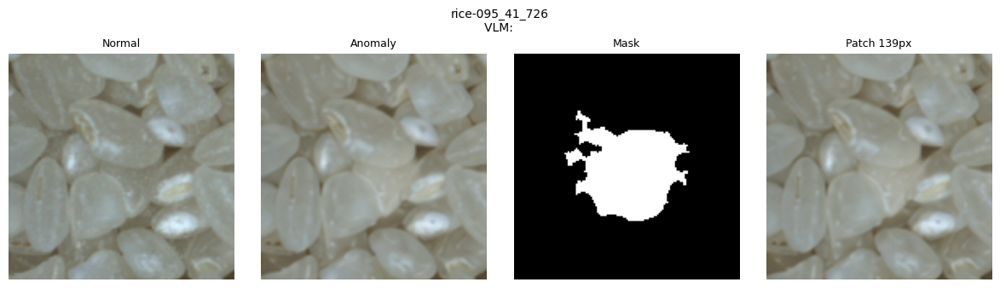

rice-095_41_726  approve into bank? (y / n / s to stop):  n


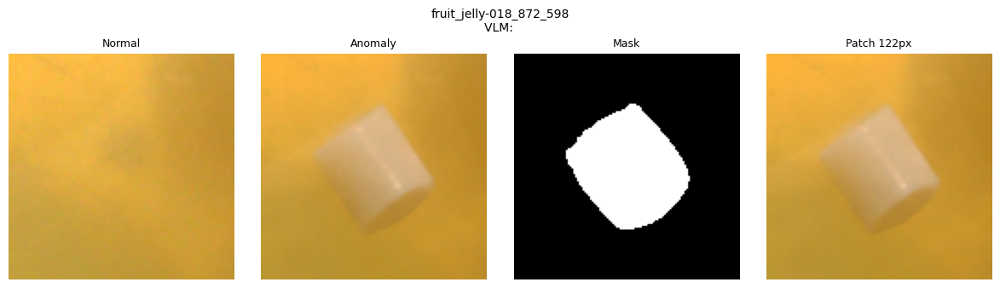

fruit_jelly-018_872_598  approve into bank? (y / n / s to stop):  y


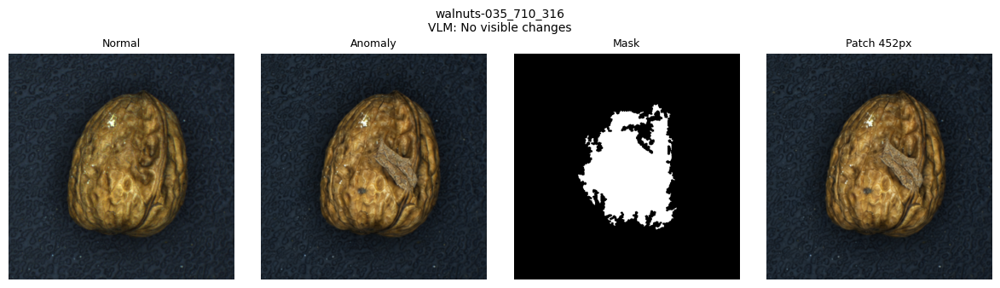

walnuts-035_710_316  approve into bank? (y / n / s to stop):  y


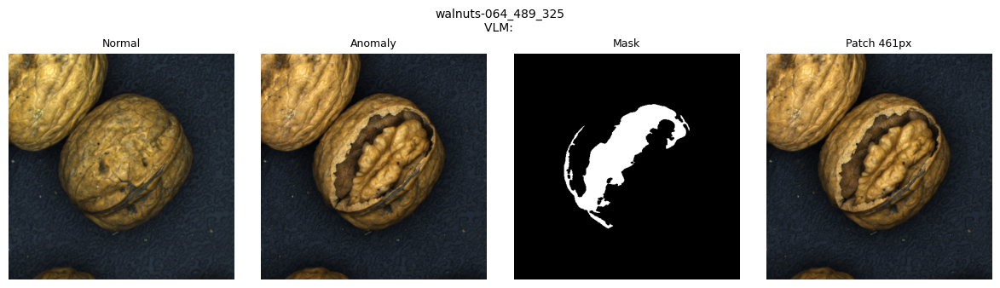

walnuts-064_489_325  approve into bank? (y / n / s to stop):  y


review_log.csv: 4 decision(s) | approved: 3


In [8]:
# Decisions saved by an earlier interactive review. Attach the review_log.csv dataset to a committed
# run so its approvals apply without asking again. Keys not in the file are still asked for.
_logs = sorted(glob.glob("/kaggle/input/**/review_log.csv", recursive=True))
prior = {}
if _logs:
    with open(_logs[0], newline="", encoding="utf-8") as fh:
        prior = {r["key"]: r["decision"] for r in csv.DictReader(fh)}
    print(f"applying {len(prior)} saved decision(s) from {_logs[0]}")

queue = [c for c in CANDS if c["status"] == "VLM REJECT"]
print(f"{len(queue)} VLM-rejected candidate(s); {sum(c['key'] in prior for c in queue)} already decided")

review_rows = []
for c in queue:
    if c["key"] in prior:
        decision = prior[c["key"]]
        if decision == "approved":
            c["status"], c["banked"] = "BANKED (human approved)", True
        review_rows.append({"key": c["key"], "cat": c["cat"], "vlm_reason": c["reason"],
                            "decision": decision})
        continue

    i = len(review_rows) + 1
    fig, ax = plt.subplots(1, 4, figsize=(12, 3.4))
    ax[0].imshow(c["normal_crop"]); ax[0].set_title("Normal", fontsize=9)
    ax[1].imshow(c["anomaly_crop"]); ax[1].set_title("Anomaly", fontsize=9)
    ax[2].imshow(c["mask_crop"], cmap="gray"); ax[2].set_title("Mask", fontsize=9)
    ax[3].imshow(c["bank_rgb"]); ax[3].set_title(f"Patch {c['side']}px", fontsize=9)
    for a in ax:
        a.axis("off")
    fig.suptitle(f"{c['key']}\nVLM: {c['reason'][:110]}", fontsize=10)
    plt.tight_layout(); plt.show()

    try:
        ans = input(f"{c['key']}  approve into bank? (y / n / s to stop): ")
    except (EOFError, OSError):
        print("no interactive input: remaining candidates stay rejected. Run interactively to review.")
        break
    ans = ans.strip().lower()
    if ans == "s":
        print("review stopped")
        break
    decision = "approved" if ans == "y" else "kept rejected"
    if decision == "approved":
        c["status"], c["banked"] = "BANKED (human approved)", True
    review_rows.append({"key": c["key"], "cat": c["cat"], "vlm_reason": c["reason"],
                        "decision": decision})

with open(os.path.join(PAIRS_DIR, "review_log.csv"), "w", newline="") as fh:
    w = csv.DictWriter(fh, fieldnames=["key", "cat", "vlm_reason", "decision"])
    w.writeheader(); w.writerows(review_rows)
print(f"review_log.csv: {len(review_rows)} decision(s) | approved: "
      f"{sum(r['decision'] == 'approved' for r in review_rows)}")

### §2e · Write the bank and the logs

Banked patches go to `flash_defect_bank/<cat>/`: each is the square RGB crop with its soft mask
saved beside it as `<key>_alpha.png`. The crop is not cut to the mask, so the substrate stays.
`flash_defect_bank/manifest.csv` has one row per banked patch, with the Stage 2–3 column names.
The logs, the bank statistics table, and the VLM audit sample go to `flash_mask_recovery/`.

In [9]:
BANK_COLS = ["key", "cat", "donor", "kind", "side", "defect_long_px", "defect_frac",
             "area_px", "area_frac", "contrast", "cfrac", "ref_cfrac", "n_regions", "region_rank",
             "vlm_defect", "vlm_reason"]

# Clear the bank first: a re-run with fewer patches must not leave old patches behind,
# because Stages 4-5 would load them without a manifest row (as flash_stage23 does).
shutil.rmtree(BANK_DIR, ignore_errors=True)
os.makedirs(BANK_DIR, exist_ok=True)

index = []
for c in CANDS:
    if not c["banked"]:
        continue
    odir = os.path.join(BANK_DIR, c["cat"])
    os.makedirs(odir, exist_ok=True)
    Image.fromarray(c["bank_rgb"]).save(os.path.join(odir, f"{c['key']}.png"))
    Image.fromarray(c["bank_alpha"]).save(os.path.join(odir, f"{c['key']}_alpha.png"))
    index.append({"key": c["key"], "cat": c["cat"], "donor": c["donor"], "kind": c["kind"],
                  "side": c["side"], "defect_long_px": c["defect_long_px"],
                  "defect_frac": c["defect_frac"], "area_px": c["area_px"],
                  "area_frac": c["area_frac"], "contrast": c["contrast"],
                  "cfrac": c["int_cfrac"], "ref_cfrac": c["cfrac"],
                  "n_regions": c["n_regions"], "region_rank": c["region_rank"],
                  "vlm_defect": c["vlm_defect"], "vlm_reason": c["reason"]})

with open(os.path.join(BANK_DIR, "manifest.csv"), "w", newline="") as fh:
    w = csv.DictWriter(fh, fieldnames=BANK_COLS)
    w.writeheader()
    w.writerows(index)

with open(os.path.join(PAIRS_DIR, "pairs_manifest.csv"), "w", newline="") as fh:
    w = csv.DictWriter(fh, fieldnames=["cat", "id", "mask_ok", "err"])
    w.writeheader(); w.writerows(MANIFEST)

with open(os.path.join(PAIRS_DIR, "candidates.csv"), "w", newline="") as fh:
    cols = ["cat", "id", "k", "area", "side", "box", "cfrac", "contrast_pass", "status",
            "vlm_defect", "reason", "banked"]
    w = csv.DictWriter(fh, fieldnames=cols)
    w.writeheader()
    for c in CANDS:
        w.writerow({k: c[k] for k in cols})

README_BANK = """flash_defect_bank/  -- input to Stages 4-5 (FLASH synthesis)

<cat>/<key>.png          square RGB crop of the defect, substrate kept (the patch)
<cat>/<key>_alpha.png    soft defect mask for that patch, same size, 0-255
manifest.csv             one row per patch. key = file name. Use side, defect_long_px and
                         defect_frac for scale. defect_frac = defect long side / source image
                         long side. kind is a label only. cfrac and contrast are the internal
                         gate; ref_cfrac is the gate against the normal image.
"""
README_PAIRS = """flash_mask_recovery/  -- the source pairs and how each mask was recovered

<cat>/<id>_normal.png    regular image I_n (reference)
<cat>/<id>_anomaly.png   generated anomaly image I_a
<cat>/<id>_mask.png      mask recovered by DiffMask from I_n and I_a (white = defect)
pairs_manifest.csv       one row per pair: mask_ok and any error
candidates.csv           one row per recovered region: gates, VLM verdict, status, banked
bank_statistics.csv      one row per category: counts at each stage, pass rate, medians
audit_sample.csv         VLM decisions to be labelled by hand in human_label (1 defect, 0 not)
"""
with open(os.path.join(BANK_DIR, "README.txt"), "w", encoding="utf-8") as fh:
    fh.write(README_BANK)
with open(os.path.join(PAIRS_DIR, "README.txt"), "w", encoding="utf-8") as fh:
    fh.write(README_PAIRS)

print("banked:", len(index))

banked: 35


In [10]:
print(f"{'category':12s} {'pairs':>5s} {'masks ok':>8s} {'regions':>7s} {'contrast':>8s} "
      f"{'VLM yes':>7s} {'banked':>6s} {'pass %':>7s}")
for cat in CATS:
    pairs_n = sum(1 for m in MANIFEST if m["cat"] == cat)
    masks_n = sum(1 for m in MANIFEST if m["cat"] == cat and m["mask_ok"])
    sub = [c for c in CANDS if c["cat"] == cat]
    cont = sum(c["contrast_pass"] for c in sub)
    vlm = sum(1 for c in sub if c["vlm_defect"])
    banked = sum(1 for c in sub if c["banked"])
    pct = 100 * banked / len(sub) if sub else 0.0
    print(f"{cat:12s} {pairs_n:5d} {masks_n:8d} {len(sub):7d} {cont:8d} {vlm:7d} "
          f"{banked:6d} {pct:6.1f}%")

category     pairs masks ok regions contrast VLM yes banked  pass %
rice            12       12      12       12      11     11   91.7%
fruit_jelly     12       12      12       12      11     12  100.0%
walnuts         12       12      12       12      10     12  100.0%


### §2f · Bank statistics and VLM audit

**S-A2c, bank statistics.** One row per category: pairs, masks recovered, candidates, contrast
pass, VLM checks and accepts, banked patches, pass rate, and medians of the entry geometry.

**VLM audit sample.** Up to 15 accepted and 15 rejected candidates, drawn with seed 0. The
`human_label` column is left blank. Fill it in by hand (1 = real defect, 0 = not a defect), then
the agreement of the VLM with the human label is the measured accuracy of the VLM gate.

In [11]:
import random

def _med(xs):
    return round(float(np.median(xs)), 5) if xs else float("nan")

stats = []
for cat in CATS:
    sub = [c for c in CANDS if c["cat"] == cat]
    banked = [c for c in sub if c["banked"]]
    stats.append(dict(
        category=cat,
        pairs=sum(1 for m in MANIFEST if m["cat"] == cat),
        masks_ok=sum(1 for m in MANIFEST if m["cat"] == cat and m["mask_ok"]),
        candidates=len(sub),
        contrast_pass=sum(c["contrast_pass"] for c in sub),
        vlm_checked=sum(1 for c in sub if c["vlm_defect"] is not None),
        vlm_accept=sum(1 for c in sub if c["vlm_defect"]),
        banked=len(banked),
        pass_rate=round(len(banked) / len(sub), 4) if sub else 0.0,
        median_side_px=_med([c["side"] for c in banked]),
        median_defect_frac=_med([c["defect_frac"] for c in banked]),
        median_area_frac=_med([c["area_frac"] for c in banked]),
        median_cfrac=_med([c["cfrac"] for c in banked]),
        median_int_cfrac=_med([c["int_cfrac"] for c in banked]),
    ))

with open(os.path.join(PAIRS_DIR, "bank_statistics.csv"), "w", newline="") as fh:
    w = csv.DictWriter(fh, fieldnames=list(stats[0].keys()))
    w.writeheader(); w.writerows(stats)

checked = [c for c in CANDS if c["vlm_defect"] is not None]
acc = [c for c in checked if c["vlm_defect"]]
rej = [c for c in checked if not c["vlm_defect"]]
rng = random.Random(0)
sample = rng.sample(acc, min(15, len(acc))) + rng.sample(rej, min(15, len(rej)))
with open(os.path.join(PAIRS_DIR, "audit_sample.csv"), "w", newline="") as fh:
    cols = ["key", "cat", "vlm_defect", "vlm_reason", "cfrac", "int_cfrac", "side", "human_label"]
    w = csv.DictWriter(fh, fieldnames=cols)
    w.writeheader()
    for c in sample:
        w.writerow({"key": c["key"], "cat": c["cat"], "vlm_defect": c["vlm_defect"],
                    "vlm_reason": c["reason"], "cfrac": c["cfrac"], "int_cfrac": c["int_cfrac"],
                    "side": c["side"], "human_label": ""})

def show_table(rows, cols, title):
    """Print a table in the cell output, in the same columns as the CSV."""
    widths = {c: max([len(c)] + [len(str(r[c])) for r in rows]) for c in cols}
    print(f"\n{title}")
    print("  ".join(c.ljust(widths[c]) for c in cols))
    print("  ".join("-" * widths[c] for c in cols))
    for r in rows:
        print("  ".join(str(r[c]).ljust(widths[c]) for c in cols))


show_table(stats, list(stats[0].keys()), "S-A2c  bank_statistics.csv")
show_table([{"key": c["key"], "cat": c["cat"], "vlm_defect": c["vlm_defect"],
             "cfrac": c["cfrac"], "int_cfrac": c["int_cfrac"], "side": c["side"],
             "human_label": ""} for c in sample],
           ["key", "cat", "vlm_defect", "cfrac", "int_cfrac", "side", "human_label"],
           f"VLM audit sample  audit_sample.csv  ({len(sample)} rows to label)")


S-A2c  bank_statistics.csv
category     pairs  masks_ok  candidates  contrast_pass  vlm_checked  vlm_accept  banked  pass_rate  median_side_px  median_defect_frac  median_area_frac  median_cfrac  median_int_cfrac
-----------  -----  --------  ----------  -------------  -----------  ----------  ------  ---------  --------------  ------------------  ----------------  ------------  ----------------
rice         12     12        12          12             12           11          11      0.9167     175.0           0.07075             0.00293           0.8671        0.8434          
fruit_jelly  12     12        12          12             12           11          12      1.0        142.0           0.05361             0.00245           0.97935       0.97145         
walnuts      12     12        12          12             12           10          12      1.0        246.5           0.09993             0.00397           0.98435       0.99475         

VLM audit sample  audit_sample.csv  (19 r

## §3 · Pairs: normal, anomaly, mask

Per category: one row per pair with Normal, Anomaly, and Mask.

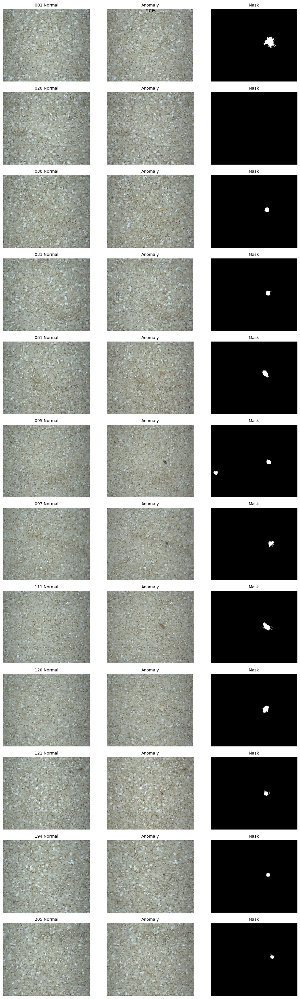

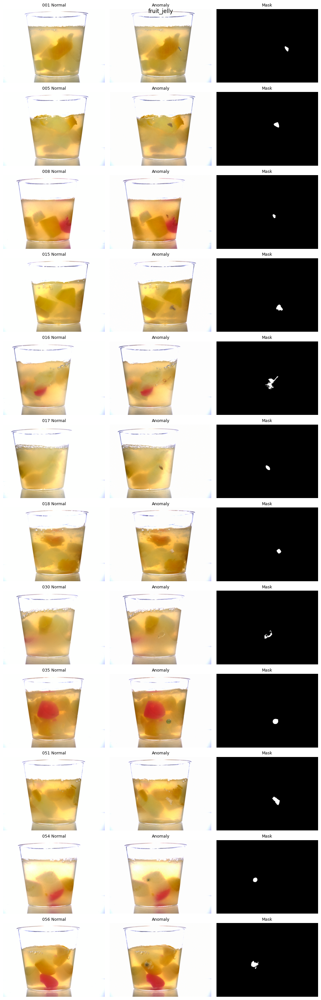

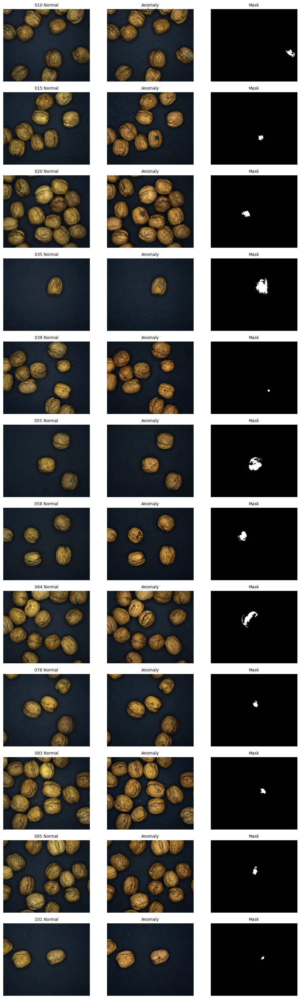

In [12]:
def pair_strip(cat):
    rows = [m for m in MANIFEST if m["cat"] == cat]
    if not rows:
        return
    fig, ax = plt.subplots(len(rows), 3, figsize=(10, 2.6 * len(rows)), squeeze=False)
    for i, m in enumerate(rows):
        pid = m["id"]
        odir = os.path.join(PAIRS_DIR, cat)
        ax[i, 0].imshow(Image.open(os.path.join(odir, f"{pid}_normal.png")))
        ax[i, 0].set_title(f"{pid} Normal", fontsize=9)
        ax[i, 1].imshow(Image.open(os.path.join(odir, f"{pid}_anomaly.png")))
        ax[i, 1].set_title("Anomaly", fontsize=9)
        if m["mask_ok"]:
            ax[i, 2].imshow(Image.open(os.path.join(odir, f"{pid}_mask.png")), cmap="gray")
            ax[i, 2].set_title("Mask", fontsize=9)
        else:
            ax[i, 2].text(0.5, 0.5, "mask failed", ha="center", va="center")
        for a in ax[i]:
            a.axis("off")
    fig.suptitle(cat, fontsize=12)
    plt.tight_layout(); plt.show()


for cat in CATS:
    pair_strip(cat)

### §3b · Every candidate patch, banked or rejected

One row per recovered region. Columns: Normal crop, Anomaly crop (red box on the crop), Mask
crop, Bank patch (the square patch that gets banked), and status with the VLM reason. Rows are
paged, 20 per figure.

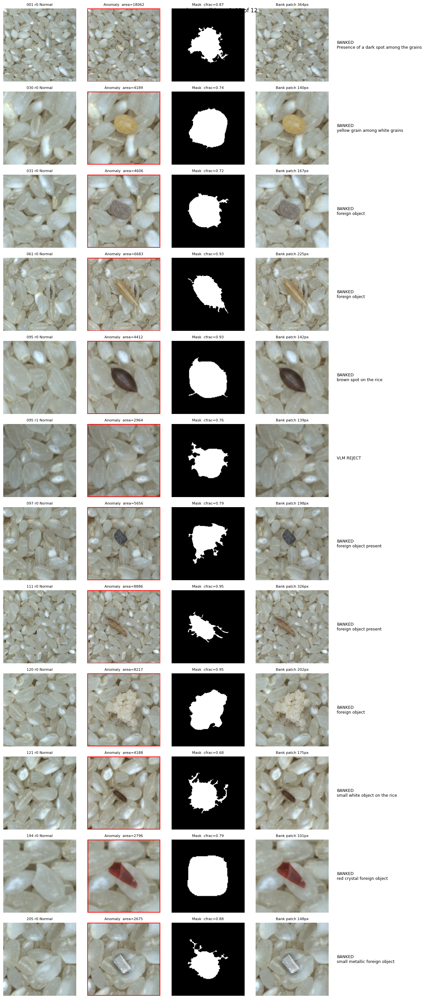

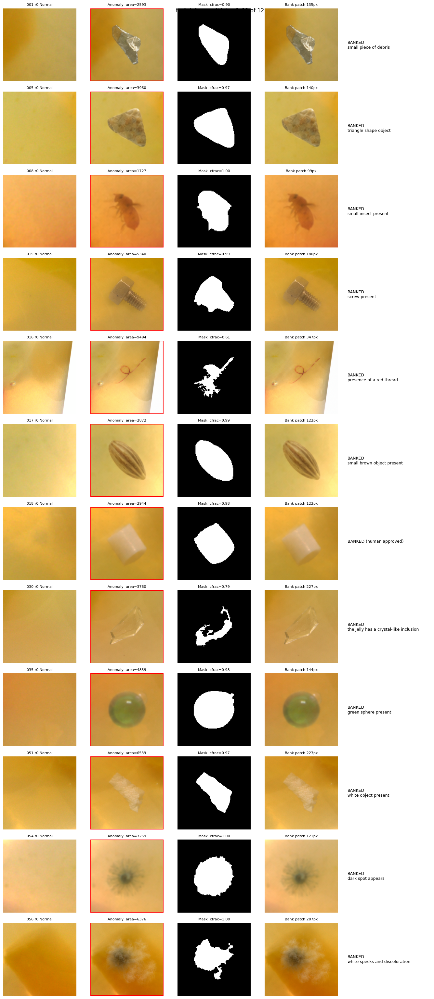

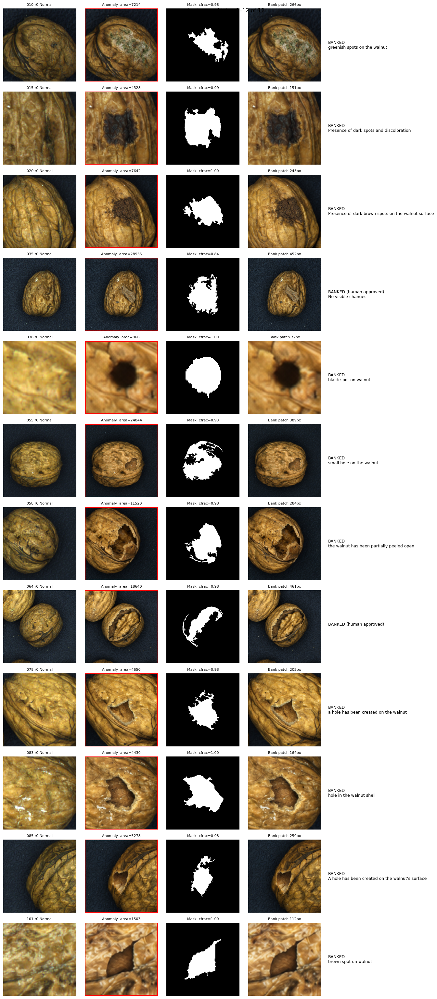

In [13]:
PAGE = 20

def patch_gallery(cat):
    sub = [c for c in CANDS if c["cat"] == cat]
    if not sub:
        return
    for start in range(0, len(sub), PAGE):
        chunk = sub[start:start + PAGE]
        fig, ax = plt.subplots(len(chunk), 5, figsize=(14, 2.6 * len(chunk)), squeeze=False)
        for i, c in enumerate(chunk):
            ax[i, 0].imshow(c["normal_crop"]); ax[i, 0].set_title(f"{c['id']} r{c['k']} Normal", fontsize=8)
            ax[i, 1].imshow(c["anomaly_crop"]); ax[i, 1].set_title(f"Anomaly  area={c['area']}", fontsize=8)
            h, w = c["anomaly_crop"].shape[:2]
            ax[i, 1].add_patch(Rectangle((0, 0), w - 1, h - 1, fill=False, edgecolor="red", lw=1.5))
            ax[i, 2].imshow(c["mask_crop"], cmap="gray"); ax[i, 2].set_title(f"Mask  cfrac={c['cfrac']:.2f}", fontsize=8)
            ax[i, 3].imshow(c["bank_rgb"]); ax[i, 3].set_title(f"Bank patch {c['side']}px", fontsize=8)
            ax[i, 4].text(0.02, 0.5, f"{c['status']}\n{c['reason'][:70]}", fontsize=9, va="center", wrap=True)
            for a in ax[i, :4]:
                a.axis("off")
            ax[i, 4].axis("off")
        fig.suptitle(f"{cat}  candidates {start + 1}–{start + len(chunk)} of {len(sub)}", fontsize=12)
        plt.tight_layout(); plt.show()


for cat in CATS:
    patch_gallery(cat)

## §11 · Upload the outputs to Google Drive

Runs last. The OAuth details are read from the Kaggle secret `DRIVE_OAUTH`, which must be attached to
this notebook. Uploads go to the Drive folder with the ID below, as the account that gave consent.
Both output folders are uploaded with their category subfolders. Existing folders and files with the same name
are updated, not duplicated. If the secret is missing, the upload is skipped and the outputs stay in
the Output tab.

In [15]:
DRIVE_FOLDER_ID = "18jH3chidIOzLn9wojGYctfBepJ-yELwb"

def upload_outputs_to_drive():
    try:
        from kaggle_secrets import UserSecretsClient
        from google.oauth2.credentials import Credentials
        from google.auth.transport.requests import Request
        from googleapiclient.discovery import build
        from googleapiclient.http import MediaFileUpload
    except ImportError as e:
        print("Drive upload skipped, missing package:", e)
        return
    try:
        info = json.loads(UserSecretsClient().get_secret("DRIVE_OAUTH"))
    except Exception as e:
        print("Drive upload skipped, secret DRIVE_OAUTH not available:", type(e).__name__)
        return

    # Upload as the account that gave consent. The refresh token renews the access token each run.
    creds = Credentials(token=None, refresh_token=info["refresh_token"],
                        token_uri="https://oauth2.googleapis.com/token",
                        client_id=info["client_id"], client_secret=info["client_secret"],
                        scopes=["https://www.googleapis.com/auth/drive"])
    creds.refresh(Request())
    drv = build("drive", "v3", credentials=creds, cache_discovery=False)

    def folder(name, parent):
        q = (f"name='{name}' and '{parent}' in parents and trashed=false and "
             "mimeType='application/vnd.google-apps.folder'")
        found = drv.files().list(q=q, fields="files(id)").execute()["files"]
        if found:
            return found[0]["id"]
        body = {"name": name, "mimeType": "application/vnd.google-apps.folder", "parents": [parent]}
        return drv.files().create(body=body, fields="id").execute()["id"]

    def upload(path, parent):
        name = os.path.basename(path)
        q = f"name='{name}' and '{parent}' in parents and trashed=false"
        found = drv.files().list(q=q, fields="files(id)").execute()["files"]
        media = MediaFileUpload(path, resumable=False)
        if found:
            drv.files().update(fileId=found[0]["id"], media_body=media).execute()
        else:
            drv.files().create(body={"name": name, "parents": [parent]},
                               media_body=media, fields="id").execute()

    n_files = 0
    for top in (BANK_DIR, PAIRS_DIR):
        top_id = folder(os.path.basename(top), DRIVE_FOLDER_ID)
        for root, dirs, files in os.walk(top):
            rel = os.path.relpath(root, top)
            parent = top_id
            if rel != ".":
                for part in rel.split(os.sep):
                    parent = folder(part, parent)
            for f in files:
                upload(os.path.join(root, f), parent)
                n_files += 1
    print(f"Drive upload done: {n_files} files into folder {DRIVE_FOLDER_ID}")

try:
    upload_outputs_to_drive()
except Exception as e:
    print("Drive upload failed:", type(e).__name__, str(e)[:300])
    print("The outputs are still in the Output tab. Check the folder is shared with the service account at Editor.")

Drive upload done: 186 files into folder 18jH3chidIOzLn9wojGYctfBepJ-yELwb


## §10 · Known limitations

- The VLM gate is unmeasured until `audit_sample.csv` is labelled by hand. Its accuracy is not
  claimed anywhere until then.
- Every accepted region is banked, as in the paper (Step 2.2). `ONE_PER_IMAGE` can limit this to one
  per image; that setting is not in the paper.
- No hand-labelled drop list. False positives from DiffMask are caught by the contrast gate and the
  VLM, not by a manual list as in `flash_part1/part2`.
- Patches the VLM rejects can be approved by a person in §2d-ii. Each approval is logged in
  `review_log.csv` and must be stated wherever the bank is described.
- DiffMask's own `--keep-ratio` (default 0.5) drops regions weaker than half the strongest one.
  The paper's Step 2.2 does not mention this filter.
- Bank size is one patch per image per category, so the bank is small. The ablation in the
  paper (A2) measures how much that size matters.